In [3]:
#################################################################################
###### Identify Number of Labour Conflict Events & Counties for Manuscript ######
#################################################################################
# This script generatates information on incidence of events for the manuscript.

# Load necessary packages
import pandas as pd

#Define the directory
directory = r'C:\Users\20234503\Dropbox\PhD Project\Research\Weather and Strikes\Project'

# Load the cleaned labour conflict event data
lconflict_county_day = pd.read_csv(directory + '\\Data\\labour_unrest_county_day_panel.csv')

print("Number of unique events and counties with events:")
print(f"Total labour unrest events: {lconflict_county_day['Labour_unrest'].sum()}")
print(f"Number of counties with at least one event: {lconflict_county_day[lconflict_county_day['Labour_unrest'] > 0 ]['FIPS'].nunique()}")

# Filter to Events Just in the United States (Contiguous US)
non_contiguous = ['AK', 'HI', 'PR', 'VI', 'GU', 'MP', 'AS', 'FM', 'MH', 'PW']
lconflict_county_day = lconflict_county_day[~lconflict_county_day['STATE'].isin(non_contiguous)]

print("Number of unique events and counties with events (contiguous US):")
print(f"Total labour unrest events: {lconflict_county_day['Labour_unrest'].sum()}")
print(f"Number of counties with at least one event: {lconflict_county_day[lconflict_county_day['Labour_unrest'] > 0]['FIPS'].nunique()}")

# Print the number of unique events and counties with events (In Summer)
lconflict_county_day['date'] = pd.to_datetime(lconflict_county_day['date'])
lconflict_county_day = lconflict_county_day[lconflict_county_day['date'].dt.month.isin([6, 7, 8])]

print("Number of unique events and counties with events (contiguous US & Summer):")
print(f"Total labour unrest events: {lconflict_county_day['Labour_unrest'].sum()}")
print(f"Number of counties with at least one event: {lconflict_county_day[lconflict_county_day['Labour_unrest'] > 0]['FIPS'].nunique()}")

# Print the number of unique events and counties with events (In Summer) - Strikes and Protests 
print("Number of unique events and counties with strike events (contiguous US & Summer):")
print(f"Total labour unrest events: {lconflict_county_day['Strike'].sum()}")
print(f"Number of counties with at least one event: {lconflict_county_day[lconflict_county_day['Strike'] > 0]['FIPS'].nunique()}")

print("Number of unique events and counties with Protest events (contiguous US & Summer):")
print(f"Total labour unrest events: {lconflict_county_day['Protest'].sum()}")
print(f"Number of counties with at least one event: {lconflict_county_day[lconflict_county_day['Protest'] > 0]['FIPS'].nunique()}")

# Print the number of unique events and counties with events (In Summer) - Healthcare and Transportation Sector
print("Number of unique events and counties with Transportation events (contiguous US & Summer):")
print(f"Total labour unrest events: {lconflict_county_day['Labour_unrest_Transport'].sum()}")
print(f"Number of counties with at least one event: {lconflict_county_day[lconflict_county_day['Labour_unrest_Transport'] > 0]['FIPS'].nunique()}")

print("Number of unique events and counties with Healthcare events (contiguous US & Summer):")
print(f"Total labour unrest events: {lconflict_county_day['Labour_unrest_Healthcare'].sum()}")
print(f"Number of counties with at least one event: {lconflict_county_day[lconflict_county_day['Labour_unrest_Healthcare'] > 0]['FIPS'].nunique()}")


Number of unique events and counties with events:
Total labour unrest events: 4095.0
Number of counties with at least one event: 659
Number of unique events and counties with events (contiguous US):
Total labour unrest events: 4019.0
Number of counties with at least one event: 638
Number of unique events and counties with events (contiguous US & Summer):
Total labour unrest events: 1106.0
Number of counties with at least one event: 338
Number of unique events and counties with strike events (contiguous US & Summer):
Total labour unrest events: 439.0
Number of counties with at least one event: 196
Number of unique events and counties with Protest events (contiguous US & Summer):
Total labour unrest events: 667.0
Number of counties with at least one event: 248
Number of unique events and counties with Transportation events (contiguous US & Summer):
Total labour unrest events: 94.0
Number of counties with at least one event: 61
Number of unique events and counties with Healthcare events (

In [4]:
# Prepare county-level conflict counts (summer months only)
lconflict_county_day['date'] = pd.to_datetime(lconflict_county_day['date'])
lconflict_county_day = lconflict_county_day[lconflict_county_day['date'].dt.month.isin([6, 7, 8])]

fips_conflict = (
    lconflict_county_day
    .groupby('FIPS')['Labour_unrest']
    .sum()                                          # <-- total count, not mean
    .reset_index()
    .rename(columns={'Labour_unrest': 'conflict_count'})
)

# ---- Check summary stats before deciding on bins ----
nonzero = fips_conflict[fips_conflict['conflict_count'] > 0]['conflict_count']

print("=== County-Level Conflict Count (non-zero only) ===")
print(nonzero.describe(percentiles=[0.25, 0.5, 0.75, 0.90, 0.95, 0.99]))
print(f"\nCounties with any conflict:  {len(nonzero)}")
print(f"Counties with no conflict:   {len(fips_conflict) - len(nonzero)}")

=== County-Level Conflict Count (non-zero only) ===
count    348.000000
mean       3.252874
std        6.366281
min        1.000000
25%        1.000000
50%        1.000000
75%        3.000000
90%        7.000000
95%       10.000000
99%       28.420000
max       74.000000
Name: conflict_count, dtype: float64

Counties with any conflict:  348
Counties with no conflict:   2921


c:\Users\20234503\AppData\Local\anaconda3\envs\Labour_Unrest_Weather_Env\Lib\site-packages\geopandas\geodataframe.py:1819: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)


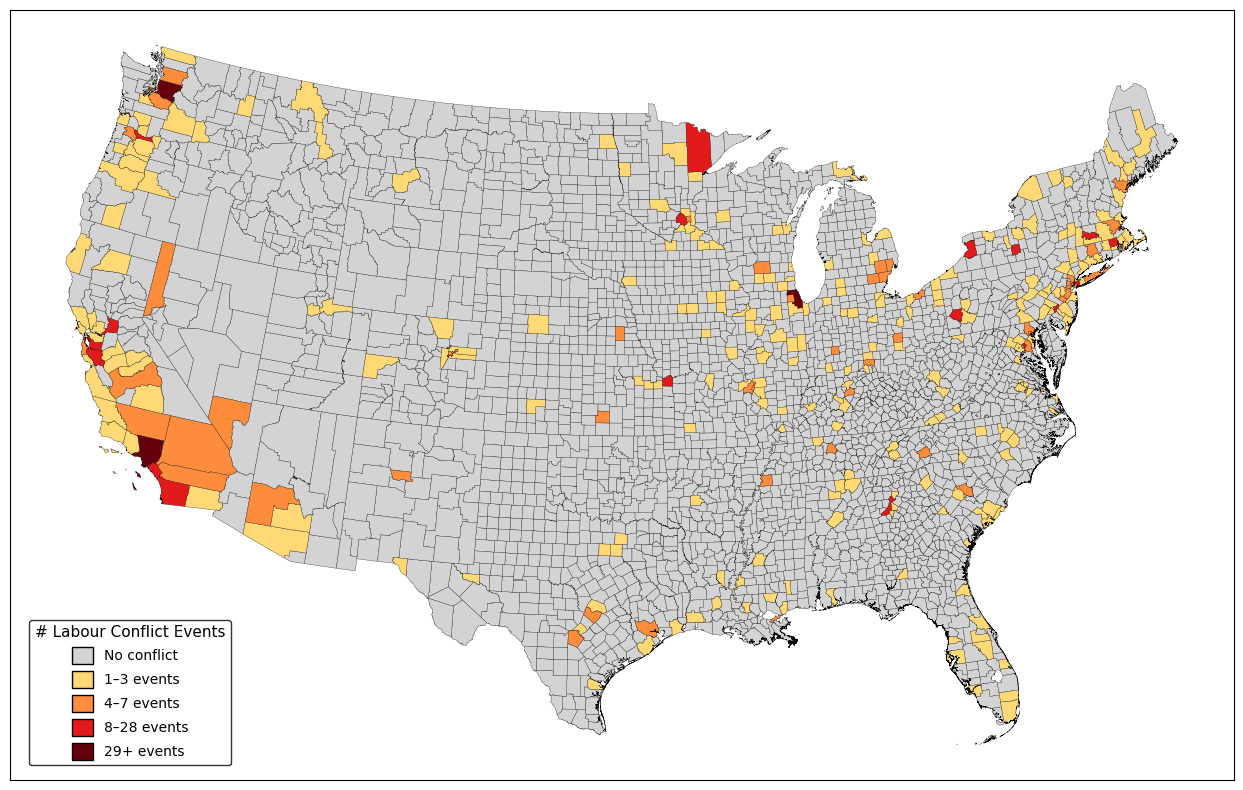

In [7]:
#################################################################
###### Geographical Distribution of Labour Conflict Events ######
#################################################################

# Load necessary packages
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Define the directory
directory = r'C:\Users\20234503\Dropbox\PhD Project\Research\Weather and Strikes\Project'

# Load the dataset
# (1) U.S. County Map
US_county_shp = gpd.read_file(directory + '\\Data\\Raw\\US Counties\\US_County_SHP\\c_05mr24.shp')
US_county_shp = gpd.GeoDataFrame(US_county_shp, geometry='geometry', crs="EPSG:4326")

# (2) County-Day Dataset
lconflict_county_day = pd.read_csv(directory + '\\Data\\labour_unrest_county_day_panel.csv')

# Reproject to EPSG:5070
US_county_shp = US_county_shp.to_crs("EPSG:5070")

# Define geographic bounding box for contiguous US (EPSG:5070)
contiguous_bounds = [-2453691.2025, 171085.9341, 2365756.5659, 3381509.2103]
contiguous = US_county_shp.cx[
    contiguous_bounds[0]:contiguous_bounds[2],
    contiguous_bounds[1]:contiguous_bounds[3]
]

# Prepare county-level conflict counts (summer months only)
lconflict_county_day['date'] = pd.to_datetime(lconflict_county_day['date'])
lconflict_county_day = lconflict_county_day[lconflict_county_day['date'].dt.month.isin([6, 7, 8])]

fips_conflict = (
    lconflict_county_day
    .groupby('FIPS')['Labour_unrest']
    .sum()
    .reset_index()
    .rename(columns={'Labour_unrest': 'conflict_count'})
)

contiguous['FIPS'] = contiguous['FIPS'].astype('int64')
contiguous_county = contiguous.merge(fips_conflict, on='FIPS', how='left')
contiguous_county['conflict_count'] = contiguous_county['conflict_count'].fillna(0)

# ---- Assign bins informed by summary statistics ----
# Distribution: median=1, p75=3, p90=7, p95=10, p99=28, max=74
# Bins capture the bulk at low counts while isolating the high-count tail
def assign_bin(count):
    if count == 0:   return 0   # no conflict
    elif count <= 3: return 1   # 1–3:  covers ~75% of conflict counties
    elif count <= 7: return 2   # 4–7:  up to p90
    elif count <= 28: return 3  # 8–28: up to p99
    else:            return 4   # 29+:  extreme outliers (top 1%)

contiguous_county['bin'] = contiguous_county['conflict_count'].apply(assign_bin)

# ---- Bin labels and colours (light yellow → dark red) ----
bin_config = {
    0: ('No conflict', '#D3D3D3'),
    1: ('1–3 events',  '#FED976'),
    2: ('4–7 events',  '#FD8D3C'),
    3: ('8–28 events', '#E31A1C'),
    4: ('29+ events',  '#67000D'),
}

# ---- Plot ----
fig, ax = plt.subplots(1, 1, figsize=(14, 8))

for val, (label, color) in bin_config.items():
    subset = contiguous_county[contiguous_county['bin'] == val]
    if not subset.empty:
        subset.plot(ax=ax, color=color, edgecolor='black', linewidth=0.2)

# ---- Legend on the left ----
legend_patches = [
    mpatches.Patch(facecolor=color, edgecolor='black', label=label)
    for val, (label, color) in bin_config.items()
]

ax.legend(
    handles=legend_patches,
    title='# Labour Conflict Events',
    title_fontsize=11,
    fontsize=10,
    loc='lower left',
    bbox_to_anchor=(0.01, 0.01),  # small inset from the bottom-left corner
    frameon=True,
    facecolor='white',
    edgecolor='black',
    handlelength=1.5,
    handleheight=1.5,
)

ax.set_xticks([])
ax.set_yticks([])
#ax.set_xlabel('Labour Conflict Incidence by County (June–August)', fontsize=16, labelpad=10)

plt.tight_layout()
plt.savefig(
    directory + r'\Results (Final)\labour_conflict_map.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

c:\Users\20234503\AppData\Local\anaconda3\envs\Labour_Unrest_Weather_Env\Lib\site-packages\geopandas\geodataframe.py:1819: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)


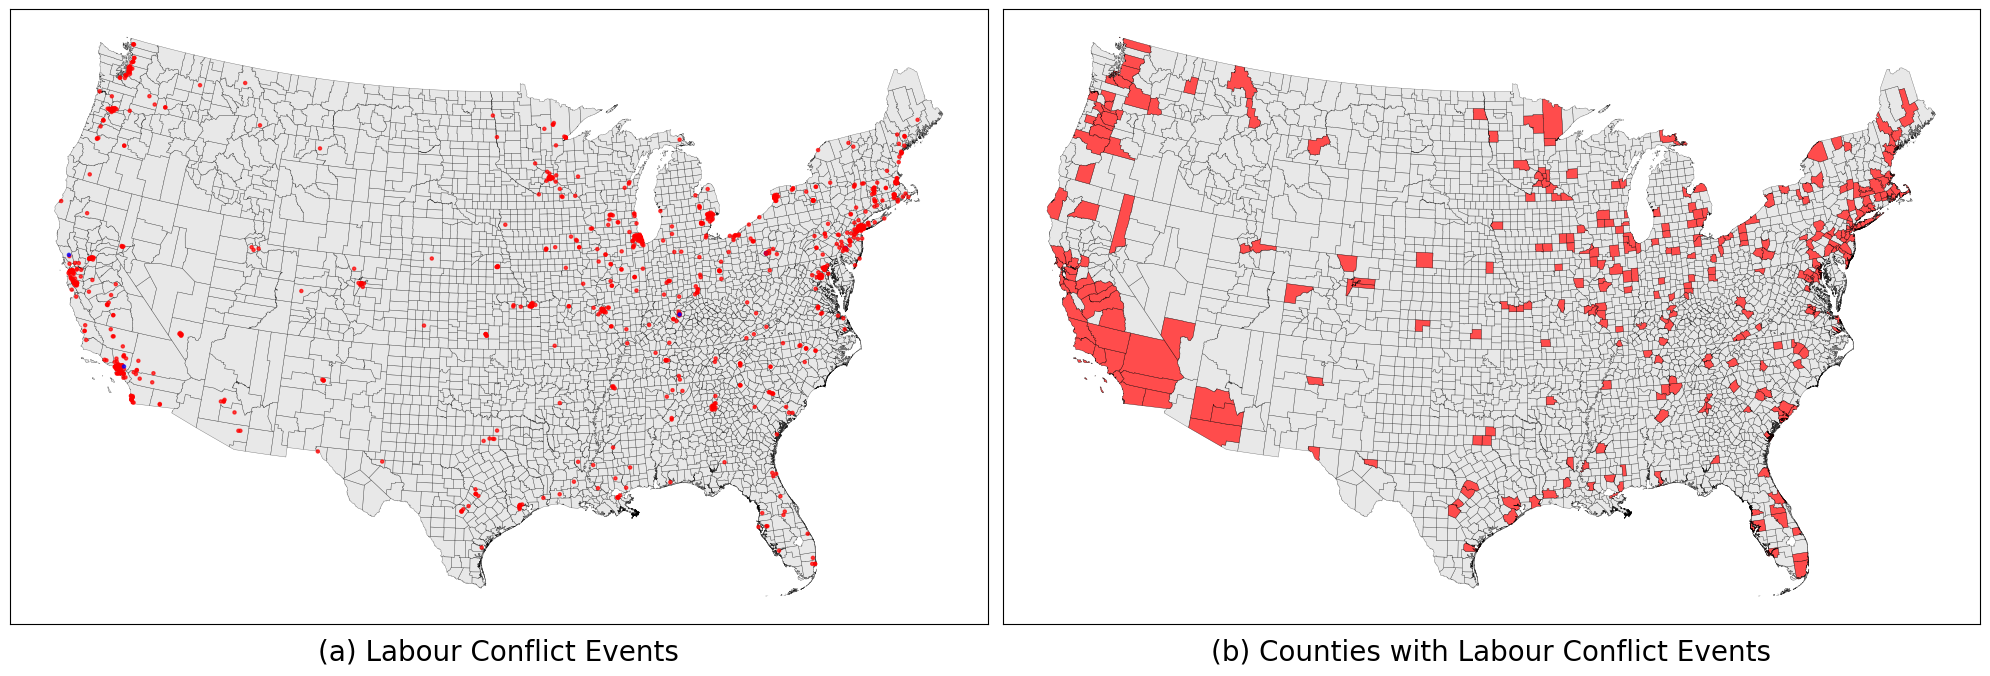

In [5]:
#################################################################
###### Geographical Distribution of Labour Conflict Events ######
#################################################################

# This script generates a map of the geographical distribution of labour conflict events.
# Panel (a) shows the exact locations of the events, while panel (b) shows counties with at least one event over the study period.

# Load necessary packages
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely import Point
from shapely.ops import unary_union

#Define the directory
directory = r'C:\Users\20234503\Dropbox\PhD Project\Research\Weather and Strikes\Project'

# Load the dataset
# (1) U.S. County Map
US_county_shp = gpd.read_file(directory+'\\Data\\Raw\\US Counties\\US_County_SHP\\c_05mr24.shp')
US_county_shp = gpd.GeoDataFrame(US_county_shp, geometry='geometry', crs="EPSG:4326")

# (2) Labour Conflict Events Dataset
lconflict_event = pd.read_csv(directory + '\\Data\\lconflict_event.csv')

# (3) County-Day Dataset
lconflict_county_day = pd.read_csv(directory + '\\Data\\labour_unrest_county_day_panel.csv')

#!# Data Preparation #!#
# (1) Prepating Event-Point for Mapping and Cutting the Map into Regions
# Convert to GeoDataFrame
lconflict_event['Start_date'] = pd.to_datetime(lconflict_event['Start_date'])
lconflict_event = lconflict_event[lconflict_event['Start_date'].dt.month.isin([6, 7, 8])]
event_points = lconflict_event[['Labour_unrest', 'Location_Latitude', 'Location_Longitude']]
geometry = [Point(xy) for xy in zip(event_points["Location_Longitude"], event_points["Location_Latitude"])]
event_gdf = gpd.GeoDataFrame(event_points, geometry=geometry, crs="EPSG:4326")

# Reproject to EPSG:5070
event_gdf = event_gdf.to_crs("EPSG:5070")
US_county_shp = US_county_shp.to_crs("EPSG:5070")

# Define geographic bounding boxes for different regions (EPSG:5070) #Use GIS to identify the correct bounding boxes!
contiguous_bounds = [-2453691.2025, 171085.9341, 2365756.5659, 3381509.2103]
alaska_bounds = [-5624079.5091, 3906729.8828, -2123879.3102, 6507096.4794]
hawaii_bounds = [-6338989.6804, 1498912.4257, -5921482.1404, 2141378.3664]
puerto_rico_bounds = [3026333.5643, -81515.6598, 3411431.8432, 76241.1847]

# Separate the regions based on bounding boxes
contiguous = US_county_shp.cx[contiguous_bounds[0]:contiguous_bounds[2],contiguous_bounds[1]:contiguous_bounds[3]]
alaska = US_county_shp.cx[alaska_bounds[0]:alaska_bounds[2], alaska_bounds[1]:alaska_bounds[3]]
hawaii = US_county_shp.cx[hawaii_bounds[0]:hawaii_bounds[2], hawaii_bounds[1]:hawaii_bounds[3]]
puerto_rico = US_county_shp.cx[puerto_rico_bounds[0]:puerto_rico_bounds[2], puerto_rico_bounds[1]:puerto_rico_bounds[3]]

# Separate regions
contiguous_event = event_gdf.cx[contiguous_bounds[0]:contiguous_bounds[2], contiguous_bounds[1]:contiguous_bounds[3]]
alaska_events = event_gdf.cx[alaska_bounds[0]:alaska_bounds[2], alaska_bounds[1]:alaska_bounds[3]]
hawaii_events = event_gdf.cx[hawaii_bounds[0]:hawaii_bounds[2], hawaii_bounds[1]:hawaii_bounds[3]]
puerto_rico_events = event_gdf.cx[puerto_rico_bounds[0]:puerto_rico_bounds[2], puerto_rico_bounds[1]:puerto_rico_bounds[3]]

# (2) Prepare the county-level data for mapping
lconflict_county_day['date'] = pd.to_datetime(lconflict_county_day['date'])
lconflict_county_day = lconflict_county_day[lconflict_county_day['date'].dt.month.isin([6, 7, 8])]
fips_conflict = (
    lconflict_county_day
    .groupby('FIPS')['Labour_unrest']
    .any()  # True if any value is non-zero/non-null
    .astype(int)
    .reset_index()
    .rename(columns={'Labour_unrest': 'any_labour_conflict'})
)
contiguous['FIPS'] = contiguous['FIPS'].astype('int64')
contiguous_county_events = contiguous.merge(fips_conflict, on='FIPS', how='left')
contiguous_county_events['any_labour_conflict'] = contiguous_county_events['any_labour_conflict'].fillna(0).astype(int)

#!# Generate the map of the geographical distribution of labour conflict events #!#

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# ---- Panel (a): Event points ----
ax = axes[0]
contiguous.plot(ax=ax, color='lightgray', edgecolor='black', linewidth=0.3, alpha=0.5)
contiguous_event.plot(
    ax=ax,
    markersize=5,
    alpha=0.7,
    color=contiguous_event['Labour_unrest'].map({0: 'blue', 1: 'red'}),
)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel('(a) Labour Conflict Events', fontsize=20, labelpad=10)

# ---- Panel (b): Counties with at least one event ----
ax = axes[1]
no_conflict = contiguous_county_events[contiguous_county_events['any_labour_conflict'] == 0]
has_conflict = contiguous_county_events[contiguous_county_events['any_labour_conflict'] == 1]
no_conflict.plot(ax=ax, color='lightgray', edgecolor='black', linewidth=0.3, alpha=0.5)
has_conflict.plot(ax=ax, color='red', edgecolor='black', linewidth=0.3, alpha=0.7)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel('(b) Counties with Labour Conflict Events', fontsize=20, labelpad=10)

plt.tight_layout()
plt.savefig(directory + r'\Results (Final)\labour_conflict_map.png', dpi=300, bbox_inches='tight')
plt.show()



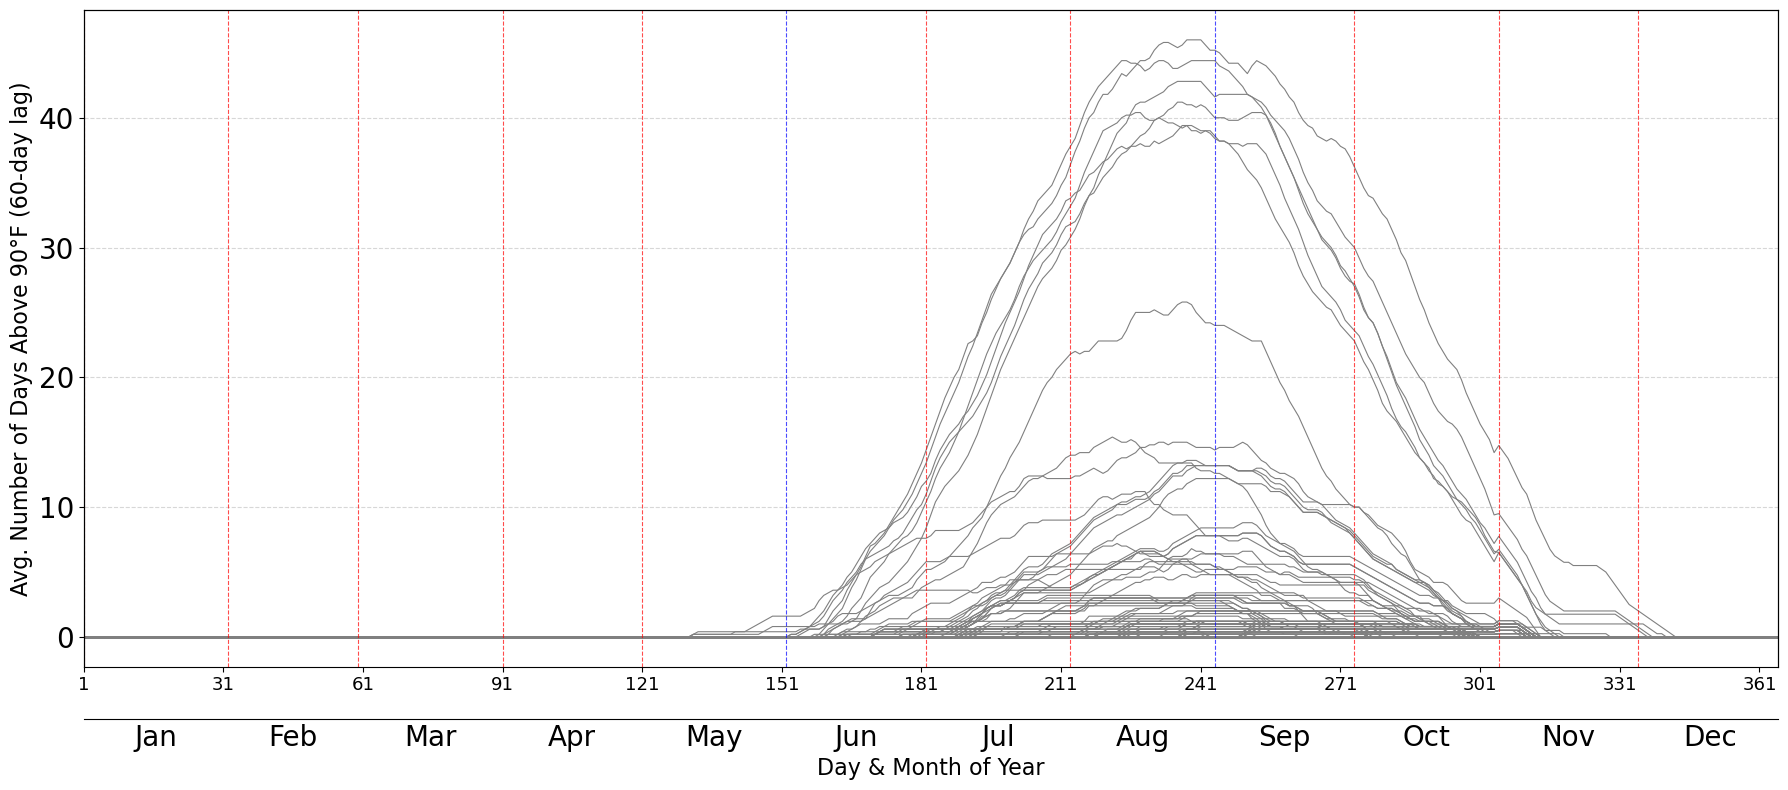

First DOY above 0 : 132 (May)
Peak DOY          : 240 (August) (avg = 0.780)
Last DOY above 0  : 342 (December)


c:\Users\20234503\AppData\Local\anaconda3\envs\Labour_Unrest_Weather_Env\Lib\site-packages\geopandas\geodataframe.py:1819: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)


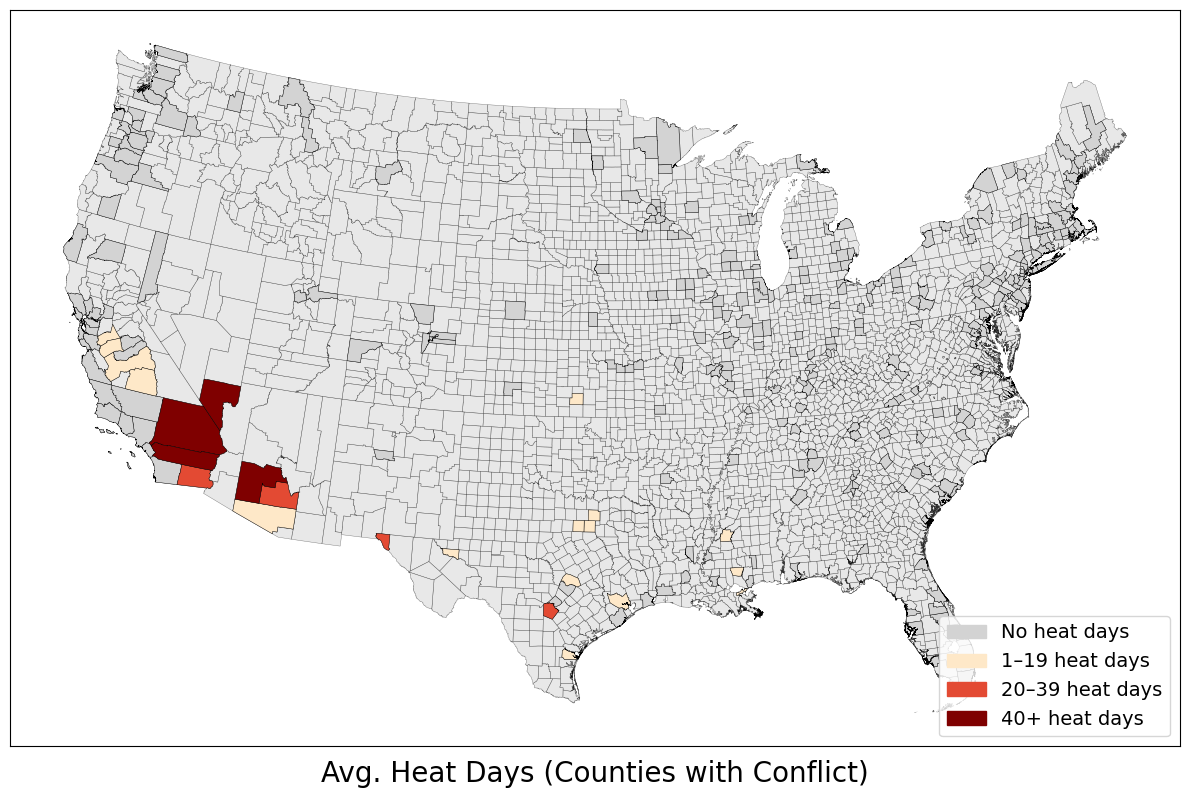

In [1]:
#############################################################################
###### Geographical and Temporal Distribution of Labour Conflict Events ######
##############################################################################

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import datetime

# Define the directory
directory = r'C:\Users\20234503\Dropbox\PhD Project\Research\Weather and Strikes\Project'

##################################################
####### Load Data                           ######
##################################################

# (1) U.S. County Shapefile
US_county_shp = gpd.read_file(directory + '\\Data\\Raw\\US Counties\\US_County_SHP\\c_05mr24.shp')
US_county_shp = gpd.GeoDataFrame(US_county_shp, geometry='geometry', crs="EPSG:4326")
US_county_shp = US_county_shp.to_crs("EPSG:5070")

# Contiguous U.S. bounding box (EPSG:5070)
contiguous_bounds = [-2453691.2025, 171085.9341, 2365756.5659, 3381509.2103]
contiguous = US_county_shp.cx[
    contiguous_bounds[0]:contiguous_bounds[2],
    contiguous_bounds[1]:contiguous_bounds[3]
]

# (2) County-Day Dataset
lconflict_county_day = pd.read_csv(directory + '\\Data\\Weather_Labour_Unrest_Event.csv')
lconflict_county_day['date'] = pd.to_datetime(lconflict_county_day['date'])

#################################################
####### Temporal Distribution               ######
##################################################

# Toggle: True = one line per county (opaque grey), False = single average line
PER_COUNTY = True

# Keep only required columns
filtered = lconflict_county_day[['date', 'FIPS', 'nn_tavg_above_90_lag_60d', 'Labour_unrest']].copy()
filtered['day_of_year'] = filtered['date'].dt.dayofyear

# Counties with at least one conflict event
fips_with_unrest = (
    filtered.groupby('FIPS')['Labour_unrest']
    .sum()
    .loc[lambda x: x > 0]
    .index
)

unrest_data = filtered[filtered['FIPS'].isin(fips_with_unrest)]

# Single average line
fips_heat_time_unrest = (
    unrest_data
    .groupby('day_of_year')['nn_tavg_above_90_lag_60d']
    .mean()
    .reset_index()
    .rename(columns={'nn_tavg_above_90_lag_60d': 'avg_above_90_lag_60d'})
)

# Per-county averages
per_county = (
    unrest_data
    .groupby(['FIPS', 'day_of_year'])['nn_tavg_above_90_lag_60d']
    .mean()
    .reset_index()
)

# Month labels
month_starts = [datetime.date(2001, m, 1).timetuple().tm_yday for m in range(1, 13)]
month_labels = [datetime.date(2001, m, 1).strftime('%b') for m in range(1, 13)]
month_mids = [
    (month_starts[i] + (month_starts[i + 1] if i + 1 < len(month_starts) else 366)) / 2
    for i in range(len(month_starts))
]

# Plot
fig, ax = plt.subplots(figsize=(18, 8))

if PER_COUNTY:
    for fips, grp in per_county.groupby('FIPS'):
        grp = grp.sort_values('day_of_year')
        ax.plot(
            grp['day_of_year'],
            grp['nn_tavg_above_90_lag_60d'],
            color='grey',
            linewidth=0.8,
            alpha=1.0
        )
    # single proxy entry for legend
    ax.plot([], [], color='grey', linewidth=0.8, label='Counties with Labour Unrest')
else:
    ax.plot(
        fips_heat_time_unrest['day_of_year'],
        fips_heat_time_unrest['avg_above_90_lag_60d'],
        label='Counties with Labour Unrest',
        color='black',
        linewidth=1.5
    )

for month, day in enumerate(month_starts, start=1):
    if month in [6, 9]:
        ax.axvline(x=day, color='blue', linestyle='--', linewidth=0.8, alpha=0.7)
    else:
        ax.axvline(x=day, color='red', linestyle='--', linewidth=0.8, alpha=0.7)

ax.set_xlim(1, 365)

# DOY ticks and label on primary x-axis
doy_ticks = list(range(1, 366, 30))
ax.set_xticks(doy_ticks)
ax.set_xticklabels(doy_ticks, fontsize=13)
ax.set_xlabel('Day & Month of Year', fontsize=16, labelpad=45)

ax.set_ylabel('Avg. Number of Days Above 90°F (60-day lag)', fontsize=16)
ax.tick_params(axis='y', labelsize=20)
ax.grid(axis='y', linestyle='--', alpha=0.5)

# Secondary x-axis with month labels
ax2 = ax.twiny()
ax2.set_xlim(ax.get_xlim())
ax2.set_xticks(month_mids)
ax2.set_xticklabels(month_labels)
ax2.tick_params(axis='x', labelsize=20, length=0)
ax2.xaxis.set_ticks_position('bottom')
ax2.xaxis.set_label_position('bottom')
ax2.spines['bottom'].set_position(('axes', -0.08))

plt.tight_layout()
plt.savefig(directory + r'\Results (Final)\heat_exposure_over_time.png', dpi=300, bbox_inches='tight')
plt.show()

##################################################
####### Summary Statistics                  ######
##################################################

def doy_to_month(doy):
    return datetime.datetime.strptime(str(int(doy)), '%j').strftime('%B')

heat = fips_heat_time_unrest
first_doy = heat.loc[heat['avg_above_90_lag_60d'] > 0, 'day_of_year'].min()
last_doy  = heat.loc[heat['avg_above_90_lag_60d'] > 0, 'day_of_year'].max()
peak_doy  = heat.loc[heat['avg_above_90_lag_60d'].idxmax(), 'day_of_year']
peak_val  = heat['avg_above_90_lag_60d'].max()

print(f"First DOY above 0 : {first_doy} ({doy_to_month(first_doy)})")
print(f"Peak DOY          : {peak_doy} ({doy_to_month(peak_doy)}) (avg = {peak_val:.3f})")
print(f"Last DOY above 0  : {last_doy} ({doy_to_month(last_doy)})")

##################################################
####### Geographical Distribution           ######
##################################################
# Filter to summer months
lconflict_county_day = lconflict_county_day[lconflict_county_day['date'].dt.month.isin([6, 7, 8])]

# Counties with at least one labour conflict event
fips_conflict = (
    lconflict_county_day
    .groupby('FIPS')['Labour_unrest']
    .any()
    .astype(int)
    .reset_index()
    .rename(columns={'Labour_unrest': 'any_labour_conflict'})
)

# Average heat days for counties with at least one conflict event
fips_heat = (
    lconflict_county_day[lconflict_county_day['Labour_unrest'] > 0]
    .groupby('FIPS')['nn_tavg_above_90_lag_60d']
    .max()
    .reset_index()
    .rename(columns={'nn_tavg_above_90_lag_60d': 'avg_heat_days'})
)

# Merge onto shapefile
contiguous['FIPS'] = contiguous['FIPS'].astype('int64')
contiguous_county_events = contiguous.merge(fips_conflict, on='FIPS', how='left')
contiguous_county_events = contiguous_county_events.merge(fips_heat, on='FIPS', how='left')
contiguous_county_events['any_labour_conflict'] = (
    contiguous_county_events['any_labour_conflict'].fillna(0).astype(int)
)

import matplotlib.colors as mcolors
import matplotlib.patches as mpatches

# Create treatment variable matching Stata definition
def assign_treatment(x):
    if pd.isna(x):
        return np.nan
    elif x > 39:
        return 3
    elif x > 19:
        return 2
    elif x > 0:
        return 1
    else:
        return 0

contiguous_county_events['heat_cat'] = contiguous_county_events['avg_heat_days'].apply(assign_treatment)

# Define colours for each category
cat_colors = {
    0: 'lightgray',
    1: '#fee8c8',
    2: '#e34a33',
    3: '#7f0000',
}

fig, ax = plt.subplots(figsize=(12, 8))

# Plot base map
contiguous.plot(ax=ax, color='lightgray', edgecolor='black', linewidth=0.3, alpha=0.5)

# Plot each category separately
for cat, color in cat_colors.items():
    subset = contiguous_county_events[contiguous_county_events['heat_cat'] == cat]
    if len(subset) > 0:
        subset.plot(ax=ax, color=color, edgecolor='black', linewidth=0.3)

# Manual legend
labels = {
    0: 'No heat days',
    1: '1–19 heat days',
    2: '20–39 heat days',
    3: '40+ heat days',
}
patches = [mpatches.Patch(color=cat_colors[i], label=labels[i]) for i in sorted(labels)]
ax.legend(handles=patches, fontsize=14, loc='lower right')

ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel('Avg. Heat Days (Counties with Conflict)', fontsize=20, labelpad=10)

plt.tight_layout()
plt.savefig(directory + r'\Results (Final)\avg_heat_days_conflict_counties.png', dpi=300, bbox_inches='tight')
plt.show()

In [1]:
##################################################################################
###### Bar Chart Showing the Percentage of Observations Strikes or Protests ######
##################################################################################
# This script generatates figure showing the percentage of observations with strikes or protests in the summer months (June, July, August) for the manuscript.

# Load necessary packages
import pandas as pd

#Define the directory
directory = r'C:\Users\20234503\Dropbox\PhD Project\Research\Weather and Strikes\Project'

# Load the cleaned labour conflict event data
lconflict_county_day = pd.read_csv(directory + '\\Data\\labour_unrest_county_day_panel.csv')

#!# Data Preparation #!#
# Filter to Events Just in the United States (Contiguous US)
non_contiguous = ['AK', 'HI', 'PR', 'VI', 'GU', 'MP', 'AS', 'FM', 'MH', 'PW']
lconflict_county_day = lconflict_county_day[~lconflict_county_day['STATE'].isin(non_contiguous)]
# Print the number of unique events and counties with events (In Summer)
lconflict_county_day['date'] = pd.to_datetime(lconflict_county_day['date'])
lconflict_county_day = lconflict_county_day[lconflict_county_day['date'].dt.month.isin([6, 7, 8])]

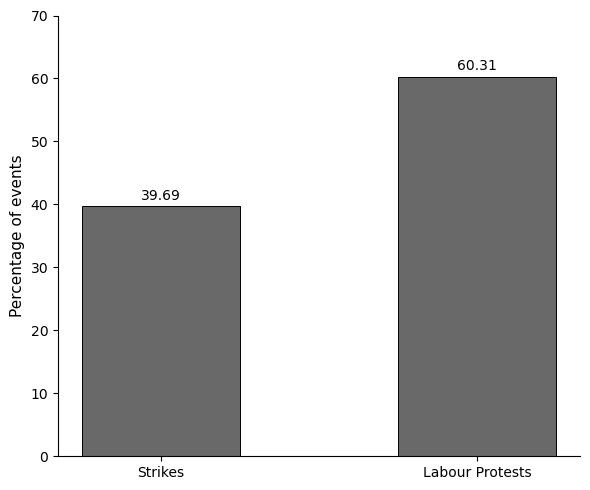

In [3]:
##################################################################################
###### Bar Chart Showing the Percentage of Observations Strikes or Protests ######
##################################################################################
# This script generatates figure showing the percentage of observations with strikes or protests in the summer months (June, July, August) for the manuscript.

# Load necessary packages
import pandas as pd
import matplotlib.pyplot as plt

#Define the directory
directory = r'C:\Users\20234503\Dropbox\PhD Project\Research\Weather and Strikes\Project'

# Load the cleaned labour conflict event data
lconflict_county_day = pd.read_csv(directory + '\\Data\\labour_unrest_county_day_panel.csv')

#!# Data Preparation #!#
# Filter to Events Just in the United States (Contiguous US)
non_contiguous = ['AK', 'HI', 'PR', 'VI', 'GU', 'MP', 'AS', 'FM', 'MH', 'PW']
lconflict_county_day = lconflict_county_day[~lconflict_county_day['STATE'].isin(non_contiguous)]
# Print the number of unique events and counties with events (In Summer)
lconflict_county_day['date'] = pd.to_datetime(lconflict_county_day['date'])
lconflict_county_day = lconflict_county_day[lconflict_county_day['date'].dt.month.isin([6, 7, 8])]

# Calculate the percentage of observations with strikes or protests
total_events = lconflict_county_day['Labour_unrest'].sum()
total_strike = lconflict_county_day['Strike'].sum()
total_protest = lconflict_county_day['Protest'].sum()

pct_strike = (total_strike / total_events) * 100
pct_protest = (total_protest / total_events) * 100

#!# Generating Figure #!#
# Plot
fig, ax = plt.subplots(figsize=(6, 5))

bars = ax.bar(
    ['Strikes', 'Labour Protests'],
    [pct_strike, pct_protest],
    color='dimgray',
    edgecolor='black',
    linewidth=0.7,
    width=0.5
)

# Add value labels on top of each bar
for bar, val in zip(bars, [pct_strike, pct_protest]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f'{val:.2f}',
        ha='center', va='bottom', fontsize=10
    )

ax.set_ylabel('Percentage of events', fontsize=11)
ax.set_xlabel('')
ax.set_ylim(0, 70)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig(directory + r'\Results (Final)\strike_vs_protest.png', dpi=300, bbox_inches='tight')
plt.show()

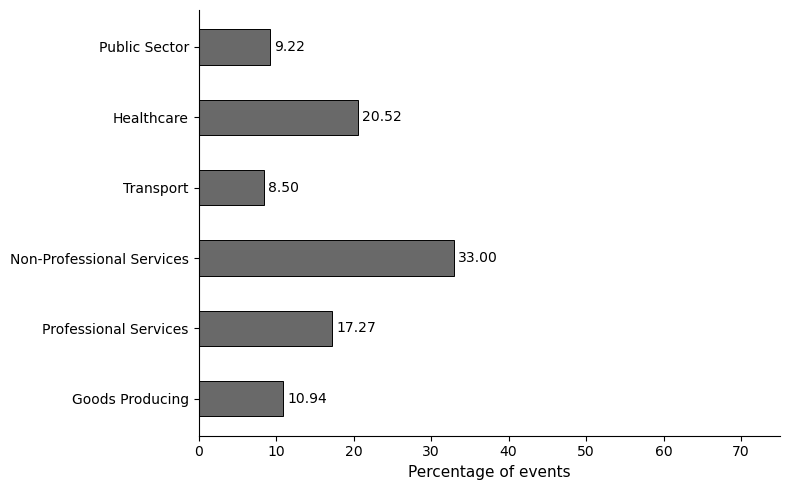

In [14]:
##################################################################################
###### Bar Chart Showing the Percentage of Observations by Broad Sector ######
##################################################################################
# This script generatates figure showing the percentage of observations by broad sector in the summer months (June, July, August) for the manuscript.

# Load necessary packages
import pandas as pd

#Define the directory
directory = r'C:\Users\20234503\Dropbox\PhD Project\Research\Weather and Strikes\Project'

# Load the cleaned labour conflict event data
lconflict_county_day = pd.read_csv(directory + '\\Data\\labour_unrest_county_day_panel.csv')

#!# Data Preparation #!#
# Filter to Events Just in the United States (Contiguous US)
non_contiguous = ['AK', 'HI', 'PR', 'VI', 'GU', 'MP', 'AS', 'FM', 'MH', 'PW']
lconflict_county_day = lconflict_county_day[~lconflict_county_day['STATE'].isin(non_contiguous)]
# Print the number of unique events and counties with events (In Summer)
lconflict_county_day['date'] = pd.to_datetime(lconflict_county_day['date'])
lconflict_county_day = lconflict_county_day[lconflict_county_day['date'].dt.month.isin([6, 7, 8])]

# Calculate the percentage of observations with strikes or protests
total_events = lconflict_county_day['Labour_unrest'].sum()
total_Goods_producing = lconflict_county_day['Labour_unrest_Goods_producing'].sum()
total_Professional_Services = lconflict_county_day['Labour_unrest_Professional_Services'].sum()
total_Non_Professional_Services = lconflict_county_day['Labour_unrest_Non_Professional_Services'].sum()
total_Transport = lconflict_county_day['Labour_unrest_Transport'].sum()
total_Healthcare = lconflict_county_day['Labour_unrest_Healthcare'].sum()
total_Public_Sector = lconflict_county_day['Labour_unrest_Public_Sector'].sum()

pct_Goods_producing = (total_Goods_producing / total_events) * 100
pct_Professional_Services = (total_Professional_Services / total_events) * 100
pct_Non_Professional_Services = (total_Non_Professional_Services / total_events) * 100
pct_Transport = (total_Transport / total_events) * 100
pct_Healthcare = (total_Healthcare / total_events) * 100
pct_Public_Sector = (total_Public_Sector / total_events) * 100

#!# Generating Figure #!#
labels = ['Goods Producing', 'Professional Services', 'Non-Professional Services', 'Transport', 'Healthcare', 'Public Sector']
values = [pct_Goods_producing, pct_Professional_Services, pct_Non_Professional_Services, pct_Transport, pct_Healthcare, pct_Public_Sector]

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.barh(
    labels,
    values,
    color='dimgray',
    edgecolor='black',
    linewidth=0.7,
    height=0.5
)

# Add value labels to the right of each bar
for bar, val in zip(bars, values):
    ax.text(
        bar.get_width() + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f'{val:.2f}',
        ha='left', va='center', fontsize=10
    )

ax.set_xlabel('Percentage of events', fontsize=11)
ax.set_ylabel('')
ax.set_xlim(0, 75)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig(directory + r'\Results (Final)\incidence_by_industry.png', dpi=300, bbox_inches='tight')
plt.show()

In [16]:
##########################################################################
# Figure of Number of Large Work Stopages Over Time and Union Membership #
##########################################################################
import os
import numpy as np
import pandas as pd

#Define the directory
directory = r'C:\Users\20234503\Dropbox\PhD Project\Research\Weather and Strikes\Project'

# Work Stopages Data
work_stopages = pd.read_excel(directory + '\\Data\\Raw\\Work Stopages\\annual-listing.xlsx')

def clean_df(df):
    # Rename columns
    df = df.rename(columns={
        "Annual work stoppages involving 1,000 or more workers, 1947 - Present": "Year",
        "Unnamed: 1": "Work stoppages",
    })
    
    # Keep only the second row
    df = df.iloc[35:81].reset_index(drop=True)
    df["Work stoppages"] = pd.to_numeric(df["Work stoppages"], errors="coerce")
    df["Year"] = pd.to_numeric(df["Year"], errors="coerce")
    df = df[["Year", "Work stoppages"]]
    return df


work_stopages = clean_df(work_stopages)

# Union Membership Data
import os
import glob

Union_Membership_directory = r'C:\Users\20234503\Dropbox\PhD Project\Research\Weather and Strikes\Project\Data\Raw\Union\Union Membership by Sector'

def clean_df_2(df, year):
    # Select columns by position (avoids year-specific column names)
    df = df.iloc[:, [0, 1, 6, 7]]
    df.columns = ["CIC", "CIC Name", "Pct. Membership", "Pct. Coverage"]
    
    df = df.iloc[2:250].reset_index(drop=True)
    df["Pct. Membership"] = pd.to_numeric(df["Pct. Membership"], errors="coerce")
    df["Pct. Coverage"] = pd.to_numeric(df["Pct. Coverage"], errors="coerce")
    df = df[["CIC", "CIC Name", "Pct. Membership", "Pct. Coverage"]]
    df = df[df['CIC'].isna()].reset_index(drop=True)
    df["Year"] = year
    return df

# Load, clean, and append all yearly files
all_files = glob.glob(os.path.join(Union_Membership_directory, 'ind_*.xlsx'))

union_membership = pd.concat([
    clean_df_2(pd.read_excel(f), int(os.path.splitext(os.path.basename(f))[0].split('_')[1]))
    for f in all_files
], ignore_index=True)

# Annual Union Membership
avg_union_membership = union_membership.groupby('Year')['Pct. Membership'].mean().reset_index()


In [ ]:
############################
# Summary Statistics Table #
############################
import os
import numpy as np
import pandas as pd

# (1) Load Data
directory = r'C:\Users\20234503\Dropbox\PhD Project\Research\Weather and Strikes\Project'
lconflict_weather_county_day = pd.read_csv(directory + '\\Data\\Weather_Labour_Unrest_Event.csv')

#!# Data Preparation #!#
# Filter to contiguous US
non_contiguous = ['AK', 'HI', 'PR', 'VI', 'GU', 'MP', 'AS', 'FM', 'MH', 'PW']
lconflict_weather_county_day = lconflict_weather_county_day[~lconflict_weather_county_day['STATE'].isin(non_contiguous)]

# Filter to summer period
lconflict_weather_county_day['date'] = pd.to_datetime(lconflict_weather_county_day['date'])
lconflict_weather_county_day = lconflict_weather_county_day[lconflict_weather_county_day['date'].dt.month.isin([6, 7, 8])]

# Filter to counties with at least one labour unrest event in the summer sample
counties_with_events = lconflict_weather_county_day.groupby('FIPS')['Labour_unrest'].sum()
counties_with_events = counties_with_events[counties_with_events > 0].index
lconflict_weather_county_day = lconflict_weather_county_day[lconflict_weather_county_day['FIPS'].isin(counties_with_events)]

# Normalise by employment
for col in ['Labour_unrest', 'Strike', 'Protest',
            'Labour_unrest_Goods_producing', 'Labour_unrest_Professional_Services',
            'Labour_unrest_Non_Professional_Services', 'Labour_unrest_Transport',
            'Labour_unrest_Healthcare', 'Labour_unrest_Public_Sector']:
    lconflict_weather_county_day[col] = (lconflict_weather_county_day[col] / lconflict_weather_county_day['emp']) * 1_000_000

# Heat Day Bins
lconflict_weather_county_day['Heat_Day_Bin_0']       = (lconflict_weather_county_day['nn_tavg_above_90_lag_60d'] == 0).astype(int)
lconflict_weather_county_day['Heat_Day_Bin_1_20']    = (lconflict_weather_county_day['nn_tavg_above_90_lag_60d'].between(1, 20)).astype(int)
lconflict_weather_county_day['Heat_Day_Bin_21_40']   = (lconflict_weather_county_day['nn_tavg_above_90_lag_60d'].between(21, 40)).astype(int)
lconflict_weather_county_day['Heat_Day_Bin_41_plus'] = (lconflict_weather_county_day['nn_tavg_above_90_lag_60d'] >= 41).astype(int)

#!# Variable Definitions #!#
panel_a_vars = [
    ('Labour_unrest',                           'Labour Conflict',                   'All labour conflict events, including strikes and protests'),
    ('Strike',                                  '\\hspace{0.5cm} Strike',            'Work stoppages where workers withhold labour'),
    ('Protest',                                 '\\hspace{0.5cm} Protest',           'Collective actions where workers do not withhold labour'),
    ('Labour_unrest_Goods_producing',           '\\hspace{0.5cm} Goods Producing',   'Agriculture, mining, utilities, construction, and manufacturing'),
    ('Labour_unrest_Professional_Services',     '\\hspace{0.5cm} Prof. Services',    'Information, finance, real estate, professional, and educational services'),
    ('Labour_unrest_Non_Professional_Services', '\\hspace{0.5cm} Non-Prof. Services','Wholesale, retail, administrative, arts, and accommodation services'),
    ('Labour_unrest_Transport',                 '\\hspace{0.5cm} Transport',         'Transportation and warehousing activities'),
    ('Labour_unrest_Healthcare',                '\\hspace{0.5cm} Healthcare',        'Health care, hospitals, residential care, and social assistance'),
    ('Labour_unrest_Public_Sector',             '\\hspace{0.5cm} Public Sector',     'Federal, state, and local government administration'),
]

panel_b_vars = [
    ('nn_tavg_above_90_lag_60d', 'Heat Days (60-day lag)',         'Days exceeding 90$^{\\circ}$F in the preceding 60-day window'),
    ('Heat_Day_Bin_0',           '\\hspace{0.5cm} 0 days',         'Share of observations with zero heat days'),
    ('Heat_Day_Bin_1_20',        '\\hspace{0.5cm} 1--20 days',     'Share of observations with 1 to 20 heat days'),
    ('Heat_Day_Bin_21_40',       '\\hspace{0.5cm} 21--40 days',    'Share of observations with 21 to 40 heat days'),
    ('Heat_Day_Bin_41_plus',     '\\hspace{0.5cm} $\\geq$41 days', 'Share of observations with more than 40 heat days'),
]

#!# Build LaTeX Table #!#
def build_latex_table(panel_a_vars, panel_b_vars, df):

    lines = []
    lines.append("\\begin{tabular}{lp{7cm}c}")
    lines.append("\\hline\\hline")
    lines.append("Variable & Description & Mean \\\\")
    lines.append("         &             & (SD) \\\\")
    lines.append("\\hline")

    # Panel A
    lines.append("\\multicolumn{3}{l}{\\textit{Panel A: Dependent Variables (Number of Events per One Million Employees)}} \\\\")
    for col, label, desc in panel_a_vars:
        mean = df[col].mean()
        sd   = df[col].std()
        lines.append(f"\\multirow{{2}}{{*}}{{{label}}} & \\multirow{{2}}{{p{{7cm}}}}{{{desc}}} & {mean:.4f} \\\\")
        lines.append(f"         &             & ({sd:.4f}) \\\\[4pt]")
    lines.append("\\hline")

    # Panel B
    lines.append("\\multicolumn{3}{l}{\\textit{Panel B: Meteorological Variables}} \\\\")
    for col, label, desc in panel_b_vars:
        mean = df[col].mean()
        sd   = df[col].std()
        lines.append(f"\\multirow{{2}}{{*}}{{{label}}} & \\multirow{{2}}{{p{{7cm}}}}{{{desc}}} & {mean:.4f} \\\\")
        lines.append(f"         &             & ({sd:.4f}) \\\\[4pt]")

    # Sample composition
    n_obs      = len(df)
    n_counties = df['FIPS'].nunique()
    lines.append("\\hline")
    lines.append(f"Observations & & {n_obs:,} \\\\")
    lines.append(f"Counties     & & {n_counties:,} \\\\")

    lines.append("\\hline\\hline")
    lines.append("\\end{tabular}")

    return '\n'.join(lines)


latex_table = build_latex_table(panel_a_vars, panel_b_vars, lconflict_weather_county_day)
print(latex_table)

outpath = directory + r"\Results (Final)\summary_stats.tex"
with open(outpath, 'w') as f:
    f.write(latex_table)

SyntaxError: unterminated string literal (detected at line 71) (3487399438.py, line 71)

In [57]:
############################
# Summary Statistics Table #
############################
import os
import numpy as np
import pandas as pd

# (1) Load Data
directory = r'C:\Users\20234503\Dropbox\PhD Project\Research\Weather and Strikes\Project'
lconflict_weather_county_day = pd.read_csv(directory + '\\Data\\Weather_Labour_Unrest_Event.csv')

#!# Data Preparation #!#
# Filter to contiguous US
non_contiguous = ['AK', 'HI', 'PR', 'VI', 'GU', 'MP', 'AS', 'FM', 'MH', 'PW']
lconflict_weather_county_day = lconflict_weather_county_day[~lconflict_weather_county_day['STATE'].isin(non_contiguous)]

# Filter to summer period
lconflict_weather_county_day['date'] = pd.to_datetime(lconflict_weather_county_day['date'])
lconflict_weather_county_day = lconflict_weather_county_day[lconflict_weather_county_day['date'].dt.month.isin([6, 7, 8])]

# Filter to counties with at least one labour unrest event in the summer sample
counties_with_events = lconflict_weather_county_day.groupby('FIPS')['Labour_unrest'].sum()
counties_with_events = counties_with_events[counties_with_events > 0].index
lconflict_weather_county_day = lconflict_weather_county_day[lconflict_weather_county_day['FIPS'].isin(counties_with_events)]

# Normalise by employment
for col in ['Labour_unrest', 'Strike', 'Protest',
            'Labour_unrest_Goods_producing', 'Labour_unrest_Professional_Services',
            'Labour_unrest_Non_Professional_Services', 'Labour_unrest_Transport',
            'Labour_unrest_Healthcare', 'Labour_unrest_Public_Sector']:
    lconflict_weather_county_day[col] = (lconflict_weather_county_day[col] / lconflict_weather_county_day['emp']) * 1_000_000

# Heat Day Bins
lconflict_weather_county_day['Heat_Day_Bin_0']       = (lconflict_weather_county_day['nn_tavg_above_90_lag_60d'] == 0).astype(int)
lconflict_weather_county_day['Heat_Day_Bin_1_20']    = (lconflict_weather_county_day['nn_tavg_above_90_lag_60d'].between(1, 20)).astype(int)
lconflict_weather_county_day['Heat_Day_Bin_21_40']   = (lconflict_weather_county_day['nn_tavg_above_90_lag_60d'].between(21, 40)).astype(int)
lconflict_weather_county_day['Heat_Day_Bin_41_plus'] = (lconflict_weather_county_day['nn_tavg_above_90_lag_60d'] >= 41).astype(int)

#!# Variable Definitions #!#
panel_a_vars = [
    ('Labour_unrest',                           'Labour Conflict',                    'All labour conflict events, including strikes and protests'),
    ('Strike',                                  '\hspace{0.5cm} Strike',              'Work stoppages where workers withhold labour'),
    ('Protest',                                 '\hspace{0.5cm} Protest',             'Collective actions where workers do not withhold labour'),
    ('Labour_unrest_Goods_producing',           '\hspace{0.5cm} Goods Producing',     'Agriculture, mining, utilities, construction, and manufacturing sectors.'),
    ('Labour_unrest_Professional_Services',     '\hspace{0.5cm} Prof. Services',      'Information, finance, real estate, professional, and educational services sectors.'),
    ('Labour_unrest_Non_Professional_Services', '\hspace{0.5cm} Non-Prof. Services',  'Wholesale, retail, administrative, arts, and accommodation services sectors.'),
    ('Labour_unrest_Transport',                 '\hspace{0.5cm} Transport',           'Transportation and warehousing activities sector.'),
    ('Labour_unrest_Healthcare',                '\hspace{0.5cm} Healthcare',          'Health care, hospitals, residential care, and social assistance sectors.'),
    ('Labour_unrest_Public_Sector',             '\hspace{0.5cm} Public Sector',       'Federal, state, and local government administration.'),
]

panel_b_vars = [
    ('nn_tavg_above_90_lag_60d', 'Heat Days (60-day lag)',       'Number of days with average temperatures exceeding 90$^{\circ}$F over the previous 60-days window'),
    ('Heat_Day_Bin_0',           '\hspace{0.5cm} 0 days',        'zero heat days'),
    ('Heat_Day_Bin_1_20',        '\hspace{0.5cm} 1--20 days',    '1 to 20 heat days'),
    ('Heat_Day_Bin_21_40',       '\hspace{0.5cm} 21--40 days',   '21 to 40 heat days'),
    ('Heat_Day_Bin_41_plus',     '\hspace{0.5cm} ≥41 days',      'More than 40 heat days'),
]

#!# Build LaTeX Table #!#
def build_latex_table(panel_a_vars, panel_b_vars, df):

    lines = []
    lines.append("\\begin{tabular}{lp{7cm}cc}")
    lines.append("\\hline\\hline")
    lines.append("Variable & Description & Mean & SD \\\\")
    lines.append("\\hline")

    # Panel A
    lines.append("\\multicolumn{4}{l}{\\textit{Panel A: Dependent Variables (Number of Events per One Million Employees)}} \\\\")
    for col, label, desc in panel_a_vars:
        mean = df[col].mean()
        sd   = df[col].std()
        lines.append(f"{label} & {desc} & {mean:.4f} & {sd:.4f} \\\\")
    lines.append("\\hline")

    # Panel B
    lines.append("\\multicolumn{4}{l}{\\textit{Panel B: Meteorological Variables}} \\\\")
    for col, label, desc in panel_b_vars:
        mean = df[col].mean()
        sd   = df[col].std()
        lines.append(f"{label} & {desc} & {mean:.4f} & {sd:.4f} \\\\")

    lines.append("\\hline\\hline")
    lines.append("\\end{tabular}")

    return '\n'.join(lines)

latex_table = build_latex_table(panel_a_vars, panel_b_vars, lconflict_weather_county_day)
print(latex_table)

outpath = directory + r"\Results (Final)\summary_stats.tex"
with open(outpath, 'w') as f:
    f.write(latex_table)

<>:42: SyntaxWarning: invalid escape sequence '\h'
<>:43: SyntaxWarning: invalid escape sequence '\h'
<>:44: SyntaxWarning: invalid escape sequence '\h'
<>:45: SyntaxWarning: invalid escape sequence '\h'
<>:46: SyntaxWarning: invalid escape sequence '\h'
<>:47: SyntaxWarning: invalid escape sequence '\h'
<>:48: SyntaxWarning: invalid escape sequence '\h'
<>:49: SyntaxWarning: invalid escape sequence '\h'
<>:53: SyntaxWarning: invalid escape sequence '\c'
<>:54: SyntaxWarning: invalid escape sequence '\h'
<>:55: SyntaxWarning: invalid escape sequence '\h'
<>:56: SyntaxWarning: invalid escape sequence '\h'
<>:57: SyntaxWarning: invalid escape sequence '\h'
<>:42: SyntaxWarning: invalid escape sequence '\h'
<>:43: SyntaxWarning: invalid escape sequence '\h'
<>:44: SyntaxWarning: invalid escape sequence '\h'
<>:45: SyntaxWarning: invalid escape sequence '\h'
<>:46: SyntaxWarning: invalid escape sequence '\h'
<>:47: SyntaxWarning: invalid escape sequence '\h'
<>:48: SyntaxWarning: invalid e

\begin{tabular}{lp{7cm}cc}
\hline\hline
Variable & Description & Mean & SD \\
\hline
\multicolumn{4}{l}{\textit{Panel A: Dependent Variables (Number of Events per One Million Employees)}} \\
Labour Conflict & All labour conflict events, including strikes and protests & 0.0956 & 4.8253 \\
\hspace{0.5cm} Strike & Work stoppages where workers withhold labour & 0.0410 & 3.3118 \\
\hspace{0.5cm} Protest & Collective actions where workers do not withhold labour & 0.0546 & 3.5099 \\
\hspace{0.5cm} Goods Producing & Agriculture, mining, utilities, construction, and manufacturing sectors. & 0.0293 & 3.2707 \\
\hspace{0.5cm} Prof. Services & Information, finance, real estate, professional, and educational services sectors. & 0.0109 & 0.8385 \\
\hspace{0.5cm} Non-Prof. Services & Wholesale, retail, administrative, arts, and accommodation services sectors. & 0.0163 & 1.3448 \\
\hspace{0.5cm} Transport & Transportation and warehousing activities sector. & 0.0055 & 0.8010 \\
\hspace{0.5cm} Healthcar

In [49]:
############################
# Summary Statistics Table #
############################
import os
import numpy as np
import pandas as pd

# (1) Load Data
directory = r'C:\Users\20234503\Dropbox\PhD Project\Research\Weather and Strikes\Project'
lconflict_weather_county_day = pd.read_csv(directory + '\\Data\\Weather_Labour_Unrest_Event.csv')

#!# Data Preparation #!#
# Filter to contiguous US
non_contiguous = ['AK', 'HI', 'PR', 'VI', 'GU', 'MP', 'AS', 'FM', 'MH', 'PW']
lconflict_weather_county_day = lconflict_weather_county_day[~lconflict_weather_county_day['STATE'].isin(non_contiguous)]

# Filter to summer period
lconflict_weather_county_day['date'] = pd.to_datetime(lconflict_weather_county_day['date'])
lconflict_weather_county_day = lconflict_weather_county_day[lconflict_weather_county_day['date'].dt.month.isin([6, 7, 8])]

# Filter to counties with at least one labour unrest event in the summer sample
counties_with_events = lconflict_weather_county_day.groupby('FIPS')['Labour_unrest'].sum()
counties_with_events = counties_with_events[counties_with_events > 0].index
lconflict_weather_county_day = lconflict_weather_county_day[lconflict_weather_county_day['FIPS'].isin(counties_with_events)]

# Normalise by employment
for col in ['Labour_unrest', 'Strike', 'Protest',
            'Labour_unrest_Goods_producing', 'Labour_unrest_Professional_Services',
            'Labour_unrest_Non_Professional_Services', 'Labour_unrest_Transport',
            'Labour_unrest_Healthcare', 'Labour_unrest_Public_Sector']:
    lconflict_weather_county_day[col] = (lconflict_weather_county_day[col] / lconflict_weather_county_day['emp']) * 1_000_000

# Heat Day Bins
lconflict_weather_county_day['Heat_Day_Bin_0']       = (lconflict_weather_county_day['nn_tavg_above_90_lag_60d'] == 0).astype(int)
lconflict_weather_county_day['Heat_Day_Bin_1_20']    = (lconflict_weather_county_day['nn_tavg_above_90_lag_60d'].between(1, 20)).astype(int)
lconflict_weather_county_day['Heat_Day_Bin_21_40']   = (lconflict_weather_county_day['nn_tavg_above_90_lag_60d'].between(21, 40)).astype(int)
lconflict_weather_county_day['Heat_Day_Bin_41_plus'] = (lconflict_weather_county_day['nn_tavg_above_90_lag_60d'] >= 41).astype(int)

#!# Variable Definitions #!#
panel_a_vars = [
    ('Labour_unrest',                        'Labour Conflict',                   'Strikes and Labour Protests'),
    ('Strike',                               '\hspace{0.5cm} Strike',             'Strikes are temporary stoppages of work'),
    ('Protest',                              '\hspace{0.5cm} Protest',            'Any action collective action without labour being withdrawing'),
    ('Labour_unrest_Goods_producing',        '\hspace{0.5cm} Goods Producing',    'Events in primary, construction, and manufacturing sectors'),
    ('Labour_unrest_Professional_Services',  '\hspace{0.5cm} Prof. Services',     'Information, Finance and Insurance, Real Estate and Rental and Leasing, Professional, Scientific, and Technical Services, Management of Companies and Enterprises, Educational Services'),
    ('Labour_unrest_Non_Professional_Services', '\hspace{0.5cm} Non-Prof. Services', 'Events in non-professional services per one million employees'),
    ('Labour_unrest_Transport',              '\hspace{0.5cm} Transport',          'Events in transport sector per one million employees'),
    ('Labour_unrest_Healthcare',             '\hspace{0.5cm} Healthcare',         'Events in healthcare sector per one million employees'),
    ('Labour_unrest_Public_Sector',          '\hspace{0.5cm} Public Sector',      'Events in public sector per one million employees'),
]

panel_b_vars = [
    ('nn_tavg_above_90_lag_60d',  'Heat Days (60-day lag)',          'Number of days in the preceding 60 days where daily average temperature exceeded 90$^{\\circ}$F'),
    ('Heat_Day_Bin_0',            '\hspace{0.5cm} 0 days',           'Share of observations with zero heat days in the 60-day window'),
    ('Heat_Day_Bin_1_20',         '\hspace{0.5cm} 1--20 days',       'Share of observations with 1 to 20 heat days in the 60-day window'),
    ('Heat_Day_Bin_21_40',        '\hspace{0.5cm} 21--40 days',      'Share of observations with 21 to 40 heat days in the 60-day window'),
    ('Heat_Day_Bin_41_plus',      '\hspace{0.5cm} 41+ days',         'Share of observations with more than 40 heat days in the 60-day window'),
]

#!# Build LaTeX Table #!#
def build_latex_table(panel_a_vars, panel_b_vars, df):

    lines = []
    lines.append("\\begin{tabular}{llc}")
    lines.append("\\hline\\hline")
    lines.append("Variable & Description & Mean (SD) \\\\")
    lines.append("\\hline")

    # Panel A
    lines.append("\\multicolumn{3}{l}{\\textit{Panel A: Dependent Variables (Number of Events per One Million Employees)}} \\\\")
    for col, label, desc in panel_a_vars:
        mean = df[col].mean()
        sd   = df[col].std()
        lines.append(f"{label} & {desc} & {mean:.4f} \\\\")
        lines.append(f" & & ({sd:.4f}) \\\\")
    lines.append("\\hline")

    # Panel B
    lines.append("\\multicolumn{3}{l}{\\textit{Panel B: Meteorological Variables}} \\\\")
    for col, label, desc in panel_b_vars:
        mean = df[col].mean()
        sd   = df[col].std()
        lines.append(f"{label} & {desc} & {mean:.4f} \\\\")
        lines.append(f" & & ({sd:.4f}) \\\\")

    lines.append("\\hline\\hline")
    # Sample composition
    n_obs      = len(df)
    n_counties = df['FIPS'].nunique()
    lines.append("\\hline")
    lines.append(f"Observations & & {n_obs:,} \\\\")
    lines.append(f"Counties & & {n_counties:,} \\\\")

    lines.append("\\hline\\hline")
    lines.append("\\end{tabular}")

    return '\n'.join(lines)


latex_table = build_latex_table(panel_a_vars, panel_b_vars, lconflict_weather_county_day)
print(latex_table)

outpath = directory + r"\Results (Final)\summary_stats.tex"
with open(outpath, 'w') as f:
   f.write(latex_table)


<>:42: SyntaxWarning: invalid escape sequence '\h'
<>:43: SyntaxWarning: invalid escape sequence '\h'
<>:44: SyntaxWarning: invalid escape sequence '\h'
<>:45: SyntaxWarning: invalid escape sequence '\h'
<>:46: SyntaxWarning: invalid escape sequence '\h'
<>:47: SyntaxWarning: invalid escape sequence '\h'
<>:48: SyntaxWarning: invalid escape sequence '\h'
<>:49: SyntaxWarning: invalid escape sequence '\h'
<>:54: SyntaxWarning: invalid escape sequence '\h'
<>:55: SyntaxWarning: invalid escape sequence '\h'
<>:56: SyntaxWarning: invalid escape sequence '\h'
<>:57: SyntaxWarning: invalid escape sequence '\h'
<>:42: SyntaxWarning: invalid escape sequence '\h'
<>:43: SyntaxWarning: invalid escape sequence '\h'
<>:44: SyntaxWarning: invalid escape sequence '\h'
<>:45: SyntaxWarning: invalid escape sequence '\h'
<>:46: SyntaxWarning: invalid escape sequence '\h'
<>:47: SyntaxWarning: invalid escape sequence '\h'
<>:48: SyntaxWarning: invalid escape sequence '\h'
<>:49: SyntaxWarning: invalid e

\begin{tabular}{llc}
\hline\hline
Variable & Description & Mean (SD) \\
\hline
\multicolumn{3}{l}{\textit{Panel A: Dependent Variables (Number of Events per One Million Employees)}} \\
Labour Conflict & Strikes and Labour Protests & 0.0956 \\
 & & (4.8253) \\
\hspace{0.5cm} Strike & Strikes are temporary stoppages of work & 0.0410 \\
 & & (3.3118) \\
\hspace{0.5cm} Protest & Any action collective action without labour being withdrawing & 0.0546 \\
 & & (3.5099) \\
\hspace{0.5cm} Goods Producing & Events in primary, construction, and manufacturing sectors & 0.0293 \\
 & & (3.2707) \\
\hspace{0.5cm} Prof. Services & Information, Finance and Insurance, Real Estate and Rental and Leasing, Professional, Scientific, and Technical Services, Management of Companies and Enterprises, Educational Services & 0.0109 \\
 & & (0.8385) \\
\hspace{0.5cm} Non-Prof. Services & Events in non-professional services per one million employees & 0.0163 \\
 & & (1.3448) \\
\hspace{0.5cm} Transport & Events in t

In [1]:
############################
# Summary Statistics Table #
############################
#Packages
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# (1) Load Labour-Conflict and Temperature Panel Data (Just the Labour Panel Currently)
#Define the directory
directory = r'C:\Users\20234503\Dropbox\PhD Project\Research\Weather and Strikes\Project'

# Load the cleaned labour conflict event data
lconflict_weather_county_day = pd.read_csv(directory + '\\Data\\Weather_Labour_Unrest_Event.csv')

# Load Samples Indicators Exported from Models (Used for Summary Statistics Table)
sample_indicators = pd.read_csv(directory + '\\Data\\model_samples.csv')
lconflict_weather_county_day = lconflict_weather_county_day.merge(
    sample_indicators,
    on='event_id',
    how='left'
)

#!# Data Preparation #!#
# Filter to counties with at least one event 
#lconflict_weather_county_day = lconflict_weather_county_day[lconflict_weather_county_day['at least one event'] == 1] // At least one event in the full sample!! Need to Fileter to just summer counties!!
# Filter to Events Just in the United States (Contiguous US)
non_contiguous = ['AK', 'HI', 'PR', 'VI', 'GU', 'MP', 'AS', 'FM', 'MH', 'PW']
lconflict_weather_county_day = lconflict_weather_county_day[~lconflict_weather_county_day['STATE'].isin(non_contiguous)]
# Filter to just the Summer period
lconflict_weather_county_day['date'] = pd.to_datetime(lconflict_weather_county_day['date'])
lconflict_weather_county_day = lconflict_weather_county_day[lconflict_weather_county_day['date'].dt.month.isin([6, 7, 8])]

# Identify counties with at least one event in the summer sample
counties_with_events = lconflict_weather_county_day.groupby('FIPS')['Labour_unrest'].sum()
counties_with_events = lconflict_weather_county_day.groupby('FIPS')['Labour_unrest'].sum()
counties_with_events = counties_with_events[counties_with_events > 0].index

# Keep only those counties
lconflict_weather_county_day = lconflict_weather_county_day[lconflict_weather_county_day['FIPS'].isin(counties_with_events)]

# Generating the number of events per one million employees
lconflict_weather_county_day['Labour_unrest'] = (lconflict_weather_county_day['Labour_unrest'] / (lconflict_weather_county_day['emp']) * 1_000_000)
lconflict_weather_county_day['Strike'] = (lconflict_weather_county_day['Strike'] / (lconflict_weather_county_day['emp']) * 1_000_000)
lconflict_weather_county_day['Protest'] = (lconflict_weather_county_day['Protest'] / (lconflict_weather_county_day['emp']) * 1_000_000)
lconflict_weather_county_day['Labour_unrest_Goods_producing'] = (lconflict_weather_county_day['Labour_unrest_Goods_producing'] / (lconflict_weather_county_day['emp']) * 1_000_000)
lconflict_weather_county_day['Labour_unrest_Professional_Services'] = (lconflict_weather_county_day['Labour_unrest_Professional_Services'] / (lconflict_weather_county_day['emp']) * 1_000_000)
lconflict_weather_county_day['Labour_unrest_Non_Professional_Services'] = (lconflict_weather_county_day['Labour_unrest_Non_Professional_Services'] / (lconflict_weather_county_day['emp']) * 1_000_000)
lconflict_weather_county_day['Labour_unrest_Transport'] = (lconflict_weather_county_day['Labour_unrest_Transport'] / (lconflict_weather_county_day['emp']) * 1_000_000)
lconflict_weather_county_day['Labour_unrest_Healthcare'] = (lconflict_weather_county_day['Labour_unrest_Healthcare'] / (lconflict_weather_county_day['emp']) * 1_000_000)
lconflict_weather_county_day['Labour_unrest_Public_Sector'] = (lconflict_weather_county_day['Labour_unrest_Public_Sector'] / (lconflict_weather_county_day['emp']) * 1_000_000)   

# --- Heat Day Bins (computed once on full df) ---
lconflict_weather_county_day['Heat_Day_Bin_0']     = (lconflict_weather_county_day['nn_tavg_above_90_lag_60d'] == 0).astype(int)
lconflict_weather_county_day['Heat_Day_Bin_1_20']  = (lconflict_weather_county_day['nn_tavg_above_90_lag_60d'].between(1, 20)).astype(int)
lconflict_weather_county_day['Heat_Day_Bin_21_40'] = (lconflict_weather_county_day['nn_tavg_above_90_lag_60d'].between(21, 40)).astype(int)
lconflict_weather_county_day['Heat_Day_Bin_41_plus'] = (lconflict_weather_county_day['nn_tavg_above_90_lag_60d'] >= 41).astype(int)

#!# Generating Table #!#
# --- Variable lists ---
vars_panel_a = [
    'Labour_unrest', 'Strike', 'Protest',
    'Labour_unrest_Goods_producing', 'Labour_unrest_Professional_Services',
    'Labour_unrest_Non_Professional_Services', 'Labour_unrest_Transport',
    'Labour_unrest_Healthcare', 'Labour_unrest_Public_Sector'
]

vars_panel_b = [
    'nn_tavg_above_90_lag_60d',
    'Heat_Day_Bin_0', 'Heat_Day_Bin_1_20', 'Heat_Day_Bin_21_40',
    'Heat_Day_Bin_41_plus'
]

# --- Pretty labels ---
labels_a = [
    'Labour Conflict', '\hspace{0.5cm} Strike', '\hspace{0.5cm} Protest',
    '\hspace{0.5cm}  Goods Producing', '\hspace{0.5cm} Professional Services',
    '\hspace{0.5cm} Non-Professional Services', '\hspace{0.5cm} Transport',
    '\hspace{0.5cm} Healthcare', '\hspace{0.5cm} Public Sector'
]

labels_b = [
    'Heat Days (60-day lag)',
    '\hspace{0.5cm} 0 days', '\hspace{0.5cm} 1-20 days', '\hspace{0.5cm} 21-40 days',
    '\hspace{0.5cm} 41+ days'
]

# --- Samples ---
samples = {
    'Full Sample':            None,
    'Preferred Model Sample': lconflict_weather_county_day['in_sample_m1'],
    'Robust Model Sample':    lconflict_weather_county_day['in_sample_m2'],
}

# --- Helper functions ---
def format_mean_sd(mean, sd):
    return f"{mean:.4f}", f"({sd:.4f})"

def build_summary_panel(df, vars_list, sample_mask=None):
    if sample_mask is not None:
        df = df[sample_mask == 1]
    rows = []
    for var in vars_list:
        mean = df[var].mean()
        sd   = df[var].std()
        rows.append(format_mean_sd(mean, sd))
    return rows

def build_panel(vars_list, labels):
    sample_stats = {
        name: build_summary_panel(lconflict_weather_county_day, vars_list, mask)
        for name, mask in samples.items()
    }
    rows = []
    for i, label in enumerate(labels):
        mean_row = {'Variable': label}
        for name in samples:
            mean_row[name] = sample_stats[name][i][0]
        rows.append(mean_row)
        sd_row = {'Variable': ''}
        for name in samples:
            sd_row[name] = sample_stats[name][i][1]
        rows.append(sd_row)
    return pd.DataFrame(rows)

def get_n(mask):
    if mask is None:
        return f"{len(lconflict_weather_county_day):,}"
    return f"{int(mask.sum()):,}"

def get_sample_stats(mask=None):
    df = lconflict_weather_county_day if mask is None else lconflict_weather_county_day[mask == 1]
    n_obs      = len(df)
    n_counties = df['FIPS'].nunique()
    return n_obs, n_counties

# --- Get stats for each sample ---
full_obs, full_counties = get_sample_stats()

panel_c_rows = []

# Observations
obs_row_vals  = {'Variable': 'Observations'}
cnty_row_vals = {'Variable': 'Counties'}
pct_obs_vals  = {'Variable': '\hspace{0.5cm} \% of Full Sample Observations'}
pct_cnty_vals = {'Variable': '\hspace{0.5cm} \% of Full Sample Counties'}

for name, mask in samples.items():
    n_obs, n_counties = get_sample_stats(mask)
    obs_row_vals[name]  = f"{n_obs:,}"
    pct_obs_vals[name]  = f"{n_obs / full_obs * 100:.1f}\%"
    cnty_row_vals[name] = f"{n_counties:,}"
    pct_cnty_vals[name] = f"{n_counties / full_counties * 100:.1f}\%"

panel_c_table = pd.DataFrame([obs_row_vals, pct_obs_vals, cnty_row_vals, pct_cnty_vals])

# --- Build panels ---
panel_a_table = build_panel(vars_panel_a, labels_a)
panel_b_table = build_panel(vars_panel_b, labels_b)

# --- Header and footer rows ---
cols = ['Variable'] + list(samples.keys())

number_row     = pd.DataFrame([{'Variable': '', 'Full Sample': '(1)', 'Preferred Model Sample': '(2)', 'Robust Model Sample': '(3)'}])
label_row      = pd.DataFrame([{'Variable': 'Full Sample', 'Full Sample': 'Preferred Model Sample', 'Preferred Model Sample': 'Robust Model Sample', 'Robust Model Sample': ''}])
panel_a_header = pd.DataFrame([{'Variable': 'Panel A: Dependent Variables (Number of Events per One Million Employees)', 'Full Sample': '', 'Preferred Model Sample': '', 'Robust Model Sample': ''}])
panel_b_header = pd.DataFrame([{'Variable': 'Panel B: Meteorological Variables', 'Full Sample': '', 'Preferred Model Sample': '', 'Robust Model Sample': ''}])
obs_row        = pd.DataFrame([{'Variable': 'Observations', **{name: get_n(mask) for name, mask in samples.items()}}])

# Building Latex table
def build_latex_table(panel_a_table, panel_b_table, panel_c_table, samples):

    col_names  = list(samples.keys())
    n_cols     = len(col_names)
    col_format = 'l' + 'c' * n_cols

    lines = []
    lines.append(f"\\begin{{tabular}}{{{col_format}}}")
    lines.append("\\hline\\hline")

    # --- Column numbers ---
    lines.append(" & " + ' & '.join([f"({i+1})" for i in range(n_cols)]) + " \\\\")

    # --- Column labels ---
    lines.append(" & " + ' & '.join(col_names) + " \\\\")
    lines.append("\\hline")

    # --- Panel A ---
    lines.append("\\multicolumn{" + str(n_cols + 1) + "}{l}{\\textit{Panel A: Dependent Variables (Number of Events per One Million Employees)}} \\\\")
    for _, row in panel_a_table.iterrows():
        cells = ' & '.join([str(row['Variable'])] + [str(row[name]) for name in col_names])
        lines.append(f"{cells} \\\\")
    lines.append("\\hline")

    # --- Panel B ---
    lines.append("\\multicolumn{" + str(n_cols + 1) + "}{l}{\\textit{Panel B: Meteorological Variables}} \\\\")
    for _, row in panel_b_table.iterrows():
        cells = ' & '.join([str(row['Variable'])] + [str(row[name]) for name in col_names])
        lines.append(f"{cells} \\\\")
    lines.append("\\hline")

    # --- Panel C ---
    lines.append("\\multicolumn{" + str(n_cols + 1) + "}{l}{\\textit{Panel C: Sample Composition}} \\\\")
    for _, row in panel_c_table.iterrows():
        cells = ' & '.join([str(row['Variable'])] + [str(row[name]) for name in col_names])
        lines.append(f"{cells} \\\\")

    lines.append("\\hline\\hline")
    lines.append("\\end{tabular}")

    return '\n'.join(lines)


latex_table = build_latex_table(panel_a_table, panel_b_table, panel_c_table, samples)
print(latex_table)

outpath = directory + r"\Results (Final)\summary_stats.tex"
with open(outpath, 'w') as f:
    f.write(latex_table)


<>:77: SyntaxWarning: invalid escape sequence '\h'
<>:77: SyntaxWarning: invalid escape sequence '\h'
<>:78: SyntaxWarning: invalid escape sequence '\h'
<>:78: SyntaxWarning: invalid escape sequence '\h'
<>:79: SyntaxWarning: invalid escape sequence '\h'
<>:79: SyntaxWarning: invalid escape sequence '\h'
<>:80: SyntaxWarning: invalid escape sequence '\h'
<>:80: SyntaxWarning: invalid escape sequence '\h'
<>:85: SyntaxWarning: invalid escape sequence '\h'
<>:85: SyntaxWarning: invalid escape sequence '\h'
<>:85: SyntaxWarning: invalid escape sequence '\h'
<>:86: SyntaxWarning: invalid escape sequence '\h'
<>:146: SyntaxWarning: invalid escape sequence '\h'
<>:147: SyntaxWarning: invalid escape sequence '\h'
<>:152: SyntaxWarning: invalid escape sequence '\%'
<>:154: SyntaxWarning: invalid escape sequence '\%'
<>:77: SyntaxWarning: invalid escape sequence '\h'
<>:77: SyntaxWarning: invalid escape sequence '\h'
<>:78: SyntaxWarning: invalid escape sequence '\h'
<>:78: SyntaxWarning: inval

KeyboardInterrupt: 

In [5]:
from scipy import stats

def test_sample_differences(df, sample_col, vars_to_test):
    full   = df
    sample = df[df[sample_col] == 1]
    
    results = []
    for var in vars_to_test:
        full_vals   = full[var].dropna()
        sample_vals = sample[var].dropna()
        
        t_stat, p_val = stats.ttest_ind(full_vals, sample_vals, equal_var=False)
        
        results.append({
            'Variable':      var,
            'Mean (Full)':   full_vals.mean(),
            'Mean (Sample)': sample_vals.mean(),
            'Difference':    sample_vals.mean() - full_vals.mean(),
            'p-value':       p_val,
        })
    
    return pd.DataFrame(results)


vars_to_test = [
    'Labour_unrest',
    'nn_tavg_above_90_lag_60d'
]

diff_m1 = test_sample_differences(lconflict_weather_county_day, 'in_sample_m1', vars_to_test)
diff_m2 = test_sample_differences(lconflict_weather_county_day, 'in_sample_m2', vars_to_test)


def build_latex_difference_table(diff_m1, diff_m2):

    def get_stars(p_val):
        if p_val < 0.01:
            return '***'
        elif p_val < 0.05:
            return '**'
        elif p_val < 0.10:
            return '*'
        return ''

    var_labels = {
        'Labour_unrest':            'Labour Conflict',
        'nn_tavg_above_90_lag_60d': 'Heat Days (60-day lag)',
    }

    lines = []
    lines.append("\\begin{tabular}{lccccc}")
    lines.append("\\hline\\hline")
    lines.append(" & (1) & \multicolumn{2}{c}{(2)}  & \multicolumn{2}{c}{(3)} \\\\")
    lines.append(" & Full Sample & \multicolumn{2}{c}{Preferred Model}  & \multicolumn{2}{c}{Robust Model} \\\\")
    lines.append(" & Mean & Mean & (2)-(1) & Mean & (3)-(1) \\\\")
    lines.append("\\hline")

    for i, row_m1 in diff_m1.iterrows():
        row_m2      = diff_m2.iloc[i]
        var         = row_m1['Variable']
        label       = var_labels.get(var, var)
        
        mean_full   = f"{row_m1['Mean (Full)']:.4f}"
        
        mean_m1     = f"{row_m1['Mean (Sample)']:.4f}"
        diff_m1_val = f"{row_m1['Difference']:.4f}{get_stars(row_m1['p-value'])}"
        
        mean_m2     = f"{row_m2['Mean (Sample)']:.4f}"
        diff_m2_val = f"{row_m2['Difference']:.4f}{get_stars(row_m2['p-value'])}"

        lines.append(f"{label} & {mean_full} & {mean_m1} & {diff_m1_val} & {mean_m2} & {diff_m2_val} \\\\")

    lines.append("\\hline\\hline")
    lines.append("\\end{tabular}")

    return '\n'.join(lines)


latex_diff_table = build_latex_difference_table(diff_m1, diff_m2)
print(latex_diff_table)

outpath_diff = directory + r"\Results (Final)\sample_differences.tex"
with open(outpath_diff, 'w') as f:
    f.write(latex_diff_table)

<>:53: SyntaxWarning: invalid escape sequence '\m'
<>:54: SyntaxWarning: invalid escape sequence '\m'
<>:53: SyntaxWarning: invalid escape sequence '\m'
<>:54: SyntaxWarning: invalid escape sequence '\m'
C:\Users\20234503\AppData\Local\Temp\ipykernel_25400\3691057410.py:53: SyntaxWarning: invalid escape sequence '\m'
  lines.append(" & (1) & \multicolumn{2}{c}{(2)}  & \multicolumn{2}{c}{(3)} \\\\")
C:\Users\20234503\AppData\Local\Temp\ipykernel_25400\3691057410.py:54: SyntaxWarning: invalid escape sequence '\m'
  lines.append(" & Full Sample & \multicolumn{2}{c}{Preferred Model}  & \multicolumn{2}{c}{Robust Model} \\\\")


\begin{tabular}{lccccc}
\hline\hline
 & (1) & \multicolumn{2}{c}{(2)}  & \multicolumn{2}{c}{(3)} \\
 & Full Sample & \multicolumn{2}{c}{Preferred Model}  & \multicolumn{2}{c}{Robust Model} \\
 & Mean & Mean & (2)-(1) & Mean & (3)-(1) \\
\hline
Labour Conflict & 0.0956 & 0.0956 & 0.0000 & 0.1882 & 0.0926*** \\
Heat Days (60-day lag) & 0.5581 & 0.5581 & 0.0000 & 0.6700 & 0.1119*** \\
\hline\hline
\end{tabular}


In [20]:
############################################
# Compute % missing for selected variables #
############################################
# (1) Importing Labour Conflict Event Data
lconflict_event = pd.read_csv(directory + '\\Data\\labour_action_tracker_05012026.csv')

lconflict_event = lconflict_event.replace(r'^\s*$', pd.NA, regex=True) # Replace blank (empty string) values with missing (NaN) in the DataFrame

n_missing = lconflict_event['Employer'].isna().sum()
n_missing_df = lconflict_event[lconflict_event['Employer'].isna()]
print(f"Number of missing observations in Employer: {n_missing}")
lconflict_event = lconflict_event.dropna(subset=['Employer']).reset_index(drop=True) #Dropping rows with missing Employer values

lconflict_event['UniqueID'] = range(len(lconflict_event))

# (2)  Filtering to the contiguous US and summer months
# Filter to Events Just in the United States (Contiguous US)
non_contiguous = ['Alaska', 'Hawaii', 'Puerto Rico', 'U.S. Virgin Islands', 'Guam', 'District of Columbia']
lconflict_event = lconflict_event[~lconflict_event['Location_State'].isin(non_contiguous)]
# Print the number of unique events and counties with events (In Summer)
lconflict_event['Start_date'] = pd.to_datetime(lconflict_event['Start_date'])
lconflict_event = lconflict_event[lconflict_event['Start_date'].dt.month.isin([6, 7, 8])]

# (3) Generate the LaTeX table with % signs for the missing data summary
missing_perc = {
    "Employer": lconflict_event['Employer'].isna().mean() * 100,
    "Labor Organization": lconflict_event['Labor_Organization'].isna().mean() * 100,
    "Industry": lconflict_event['Industry'].isna().mean() * 100,
    "Bargaining Unit Size": lconflict_event['Bargaining_Unit_Size'].isna().mean() * 100,
    "Approximate Number of Participants": lconflict_event['Approximate_Number_of_Participants'].isna().mean() * 100,
    "Start Date": lconflict_event['Start_date'].isna().mean() * 100,
    "End Date": lconflict_event['End_date'].isna().mean() * 100,
    "Strike or Protest": lconflict_event['Action_type'].isna().mean() * 100,
    "Worker Demands": lconflict_event['Worker_demands'].isna().mean() * 100
}

# Create summary DataFrame, rounded to 1 decimal
missing_data_summary = (
    pd.DataFrame(list(missing_perc.items()), columns=["Variable", "% Missing"])
    .assign(**{"% Missing": lambda x: x["% Missing"].round(2)})
    .sort_values("% Missing", ascending=False)
    .reset_index(drop=True)
)

outpath = directory + r"\Results (Final)\missing_data_summary.tex"

# Make a copy so we don't overwrite the numeric version
latex_df = missing_data_summary.copy()

# Format "% Missing" as string with one decimal + percent sign
latex_df["% Missing"] = latex_df["% Missing"].map(lambda x: f"{x:.1f}\\%")

# Export tabular section only
with open(outpath, 'w') as f:
    f.write(latex_df.to_latex(
        index=False,
        column_format="l r",
        escape=False
    ))

print(f"LaTeX table with % signs saved to: {outpath}")

Number of missing observations in Employer: 326
LaTeX table with % signs saved to: C:\Users\20234503\Dropbox\PhD Project\Research\Weather and Strikes\Project\Results (Final)\missing_data_summary.tex


In [8]:
######################################################################################################
###### Composite occupational measure of risk of exposure to these risks factors across sectors. #####
######################################################################################################

# Packages
import pandas as pd
import numpy as np

# Directory
directory = r'C:\Users\20234503\Dropbox\PhD Project\Research\Weather and Strikes\Project'


# =============================================================================
# (1) Occupational Composition of Sectors (OEWS)
# =============================================================================

OEWS = pd.read_excel(
    directory + r"\Data\Raw\Exposure\natsector_M2024_dl.xlsx",
    dtype=str
)
OEWS = OEWS[OEWS['O_GROUP'] == 'detailed']          # Keep only 6-digit occupation codes
selected_columns = ['NAICS', 'NAICS_TITLE', 'OCC_CODE', 'OCC_TITLE', 'TOT_EMP', 'PCT_TOTAL']
OEWS = OEWS[selected_columns]
OEWS['PCT_TOTAL'] = pd.to_numeric(OEWS['PCT_TOTAL'], errors='coerce')

# Data quality check: PCT_TOTAL should sum to ~100 per sector; deviations indicate suppressed BLS data
by_naics = (OEWS
            .dropna(subset=['NAICS'])
            .groupby('NAICS', as_index=True)['PCT_TOTAL']
            .sum()
            .sort_values(ascending=False))
print(by_naics)


# =============================================================================
# (2) Occupational Exposure Data (O*NET)
# =============================================================================

ONet_Hot_cold = pd.read_csv(
    directory + r"\Data\Raw\Exposure\Exposed_to_Very_Hot_or_Cold_Temperatures.csv",
)
ONet_Physical = pd.read_csv(
    directory + r"\Data\Raw\Exposure\Performing_General_Physical_Activities.csv",
)


# -----------------------------------------------------------------------------
# (2a) Hot/Cold Temperature Exposure
# How often does this job require working in very hot (>90°F) or very cold (<32°F) temperatures?
# Context score: 0 = Never, 1–25 = Yearly, 26–50 = Monthly, 51–75 = Weekly, 76–100 = Daily
# -----------------------------------------------------------------------------

ONet_Hot_cold['Context'] = pd.to_numeric(ONet_Hot_cold['Context'], errors='coerce')

# Keep only 6-digit SOC codes and strip decimal suffix (e.g. "15-1252.00" → "15-1252")
ONet_Hot_cold = ONet_Hot_cold[
    ONet_Hot_cold['Code'].astype('string').str.contains(r'\.00$', na=False)
]
ONet_Hot_cold['Code'] = ONet_Hot_cold['Code'].astype('string').str.replace(r'\.\d+$', '', regex=True)
ONet_Hot_cold = ONet_Hot_cold.rename(columns={'Code': 'OCC_CODE', 'Context': 'Context_HT'})

print(f"ONet_Hot_cold — OCC_CODE unique: {ONet_Hot_cold['OCC_CODE'].is_unique}")


# -----------------------------------------------------------------------------
# (2b) Physical Activity Exposure
# How often does this job require general physical activities (climbing, lifting, walking, etc.)?
# Level: 0 = Not available/relevant ... higher = more physically demanding
# -----------------------------------------------------------------------------

# Recode non-numeric Level values to 0 and convert to integer
ONet_Physical['Level'] = (
    pd.to_numeric(
        ONet_Physical['Level'].replace({'Not available': 0, 'Not relevant': 0}),
        errors='coerce'
    ).astype('Int64')
)

# Composite score: Importance × Level, then min-max normalised to [0, 100]
ONet_Physical['Phys_Multiplicative'] = ONet_Physical['Importance'] * ONet_Physical['Level']
ONet_Physical['Phys_Multiplicative'] = (
    (ONet_Physical['Phys_Multiplicative'] - ONet_Physical['Phys_Multiplicative'].min()) /
    (ONet_Physical['Phys_Multiplicative'].max() - ONet_Physical['Phys_Multiplicative'].min())
) * 100

ONet_Physical['Phys_Multiplicative'] = pd.to_numeric(ONet_Physical['Phys_Multiplicative'], errors='coerce')

# Keep only 6-digit SOC codes and strip decimal suffix
ONet_Physical = ONet_Physical[
    ONet_Physical['Code'].astype('string').str.contains(r'\.00$', na=False)
]
ONet_Physical['Code'] = ONet_Physical['Code'].astype('string').str.replace(r'\.\d+$', '', regex=True)
ONet_Physical = ONet_Physical.rename(columns={'Code': 'OCC_CODE'})

print(f"ONet_Physical — OCC_CODE unique: {ONet_Physical['OCC_CODE'].is_unique}")


# =============================================================================
# (3) Composite Exposure Index (Hot/Cold × Physical Activity)
# =============================================================================

Exposure_Phys = ONet_Hot_cold.merge(ONet_Physical, on='OCC_CODE', how='left')

# Multiplicative index: hot/cold frequency × physical intensity
Exposure_Phys['Exps_Act_Index_Multiplicative'] = (
    Exposure_Phys['Context_HT'] * Exposure_Phys['Phys_Multiplicative']
)

# Min-max normalise composite index to [0, 100]; small epsilon avoids division by zero
col = 'Exps_Act_Index_Multiplicative'
Exposure_Phys[col] = (
    (Exposure_Phys[col] - Exposure_Phys[col].min()) /
    (Exposure_Phys[col].max() - Exposure_Phys[col].min() + 1e-9)
) * 100

# =============================================================================
# (4) Sector-Level Exposure Index (OEWS × O*NET)
# =============================================================================

# Merge occupational composition (OEWS) with occupation-level exposure scores (O*NET)
Exposure_sector = OEWS.merge(Exposure_Phys, on='OCC_CODE', how='left')

# Data quality check: PCT_TOTAL should still sum to ~100 per sector after merge
by_naics = (Exposure_sector
            .dropna(subset=['NAICS'])
            .groupby('NAICS', as_index=True)['PCT_TOTAL']
            .sum()
            .sort_values(ascending=False))
print(by_naics)


# -----------------------------------------------------------------------------
# (4a) Occupation-Weighted Exposure Score by Sector
# Exps_Act_Index_Multiplicative is weighted by the occupation's share of
# employment in its sector (PCT_TOTAL / 100), then summed to the sector level
# -----------------------------------------------------------------------------

pct = pd.to_numeric(Exposure_sector['PCT_TOTAL'], errors='coerce') / 100
Exposure_sector['W_Sec_OCC_Exps_Act_Index_Multiplicative'] = (
    pct * pd.to_numeric(Exposure_sector['Exps_Act_Index_Multiplicative'], errors='coerce')
)


# -----------------------------------------------------------------------------
# (4b) Aggregate to Sector Level
# -----------------------------------------------------------------------------

Exposure_sector_agg = (
    Exposure_sector
    .groupby('NAICS')
    .agg(
        NAICS_TITLE                             = ('NAICS_TITLE',                             'first'),
        W_Sec_OCC_Exps_Act_Index_Multiplicative = ('W_Sec_OCC_Exps_Act_Index_Multiplicative', 'sum'),
    )
    .reset_index()
)
Exposure_sector_agg = Exposure_sector_agg.rename(columns={'NAICS': 'NAICS_code_first'})

# -----------------------------------------------------------------------------
# (4c) Filtering to only sectors present in Labour Conflict Data
# -----------------------------------------------------------------------------
# Load the cleaned labour conflict event data
lconflict_event = pd.read_csv(directory + '\\Data\\lconflict_event.csv')
# Filter to Events Just in the United States (Contiguous US)
non_contiguous = ['Alaska', 'Hawaii', 'Puerto Rico', 'U.S. Virgin Islands', 'Guam', 'District of Columbia']
lconflict_event = lconflict_event[~lconflict_event['Location_State'].isin(non_contiguous)]
# Print the number of unique events and counties with events (In Summer)
lconflict_event['Start_date'] = pd.to_datetime(lconflict_event['Start_date'])
lconflict_event = lconflict_event[lconflict_event['Start_date'].dt.month.isin([6, 7, 8])]
#Filter to only sectors present in the labour conflict data
sectors_in_data = lconflict_event['NAICS_code_first'].unique()
Exposure_sector_agg['in_data'] = Exposure_sector_agg['NAICS_code_first'].isin(sectors_in_data).astype(int)

# =============================================================================
# (5) Aggregate to Broad Sectors
# =============================================================================

# Map NAICS codes to broad sectors
naics_to_broad = {
    # Goods-producing
    '11': 'Goods-producing',
    '21': 'Goods-producing',
    '22': 'Goods-producing',
    '23': 'Goods-producing',
    '31': 'Goods-producing',
    '32': 'Goods-producing',
    '33': 'Goods-producing',
    # Professional Services
    '51': 'Professional Services',
    '52': 'Professional Services',
    '53': 'Professional Services',
    '54': 'Professional Services',
    '55': 'Professional Services',
    '61': 'Professional Services',
    # Non-Professional Services
    '42': 'Non-Professional Services',
    '44': 'Non-Professional Services',
    '45': 'Non-Professional Services',
    '56': 'Non-Professional Services',
    '71': 'Non-Professional Services',
    '72': 'Non-Professional Services',
    # Transport (separated due to high physical and weather exposure)
    '48': 'Transport',
    '49': 'Transport',
    # Healthcare
    '62': 'Healthcare',
    # Public Sector
    '92': 'Public Sector',
}

# Match on first 2 digits of NAICS code
Exposure_sector_agg['Broad_Sector'] = (
    Exposure_sector_agg['NAICS_code_first']
    .astype(str)
    .str[:2]
    .map(naics_to_broad)
)

# Average exposure index across all NAICS sectors within each broad sector
Exposure_broad = (
    Exposure_sector_agg
    .dropna(subset=['Broad_Sector'])
    .groupby('Broad_Sector', as_index=False)
    .agg(
        Avg_Exps_Act_Index_Multiplicative = ('W_Sec_OCC_Exps_Act_Index_Multiplicative', 'mean')
    )
)

NAICS
72       99.82
44-45    99.78
23       99.75
62       99.73
31-33    99.73
51       99.70
48-49    99.69
54       99.69
52       99.68
42       99.67
61       99.59
99       99.56
81       99.52
22       99.44
71       99.33
11       99.11
55       99.05
21       99.01
53       98.09
56       97.31
Name: PCT_TOTAL, dtype: float64
ONet_Hot_cold — OCC_CODE unique: True
ONet_Physical — OCC_CODE unique: True
NAICS
72       99.82
44-45    99.78
23       99.75
62       99.73
31-33    99.73
51       99.70
48-49    99.69
54       99.69
52       99.68
42       99.67
61       99.59
99       99.56
81       99.52
22       99.44
71       99.33
11       99.11
55       99.05
21       99.01
53       98.09
56       97.31
Name: PCT_TOTAL, dtype: float64


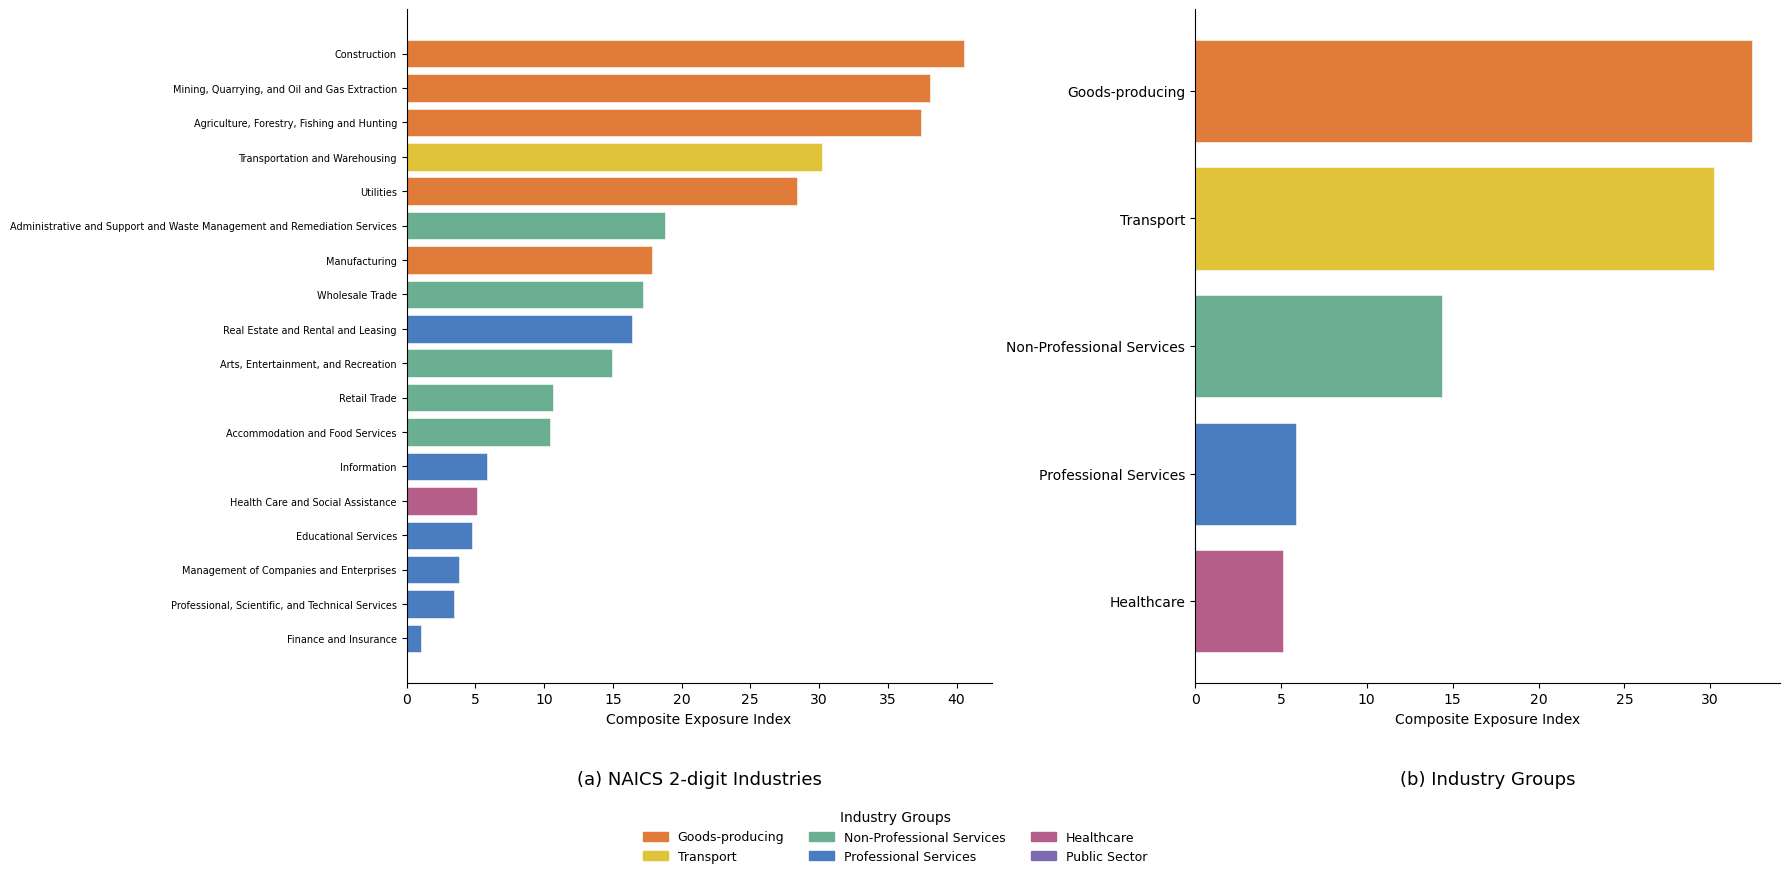

In [17]:
# =============================================================================
# (6) Visualisation — Composite Exposure Index Across Industries (Two Panels)
# =============================================================================

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Colour palette by industry group
industry_group_colours = {
    'Goods-producing'          : '#E07B39',
    'Transport'                : '#E0C339',
    'Non-Professional Services': '#6BAF92',
    'Professional Services'    : '#4A7DBF',
    'Healthcare'               : '#B55E8A',
    'Public Sector'            : '#7D6BAF',
}

# -----------------------------------------------------------------------------
# (6a) Prepare plot dataframes
# -----------------------------------------------------------------------------

# NAICS-level: drop missing, sort by exposure
Exposure_sector_agg_plot = (
    Exposure_sector_agg
    .dropna(subset=['Broad_Sector', 'W_Sec_OCC_Exps_Act_Index_Multiplicative'])
    .sort_values('W_Sec_OCC_Exps_Act_Index_Multiplicative', ascending=True)
)
Exposure_sector_agg_plot['colour'] = Exposure_sector_agg_plot['Broad_Sector'].map(industry_group_colours)

# Industry group-level: drop missing, sort by exposure
Exposure_broad_plot = (
    Exposure_broad
    .dropna(subset=['Broad_Sector', 'Avg_Exps_Act_Index_Multiplicative'])
    .sort_values('Avg_Exps_Act_Index_Multiplicative', ascending=True)
)
Exposure_broad_plot['colour'] = Exposure_broad_plot['Broad_Sector'].map(industry_group_colours)


# -----------------------------------------------------------------------------
# (6b) Plot
# -----------------------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# --- Panel (a): NAICS 2-digit Industries ---
axes[0].barh(
    Exposure_sector_agg_plot['NAICS_TITLE'],
    Exposure_sector_agg_plot['W_Sec_OCC_Exps_Act_Index_Multiplicative'],
    color=Exposure_sector_agg_plot['colour'],
    edgecolor='white',
    linewidth=0.4,
)
axes[0].set_xlabel('Composite Exposure Index', fontsize=10)
axes[0].tick_params(axis='y', labelsize=7)
axes[0].spines[['top', 'right']].set_visible(False)
axes[0].set_title('')
axes[0].annotate('(a) NAICS 2-digit Industries', xy=(0.5, -0.15), xycoords='axes fraction',
                 ha='center', fontsize=13)

# --- Panel (b): Industry Groups ---
axes[1].barh(
    Exposure_broad_plot['Broad_Sector'],
    Exposure_broad_plot['Avg_Exps_Act_Index_Multiplicative'],
    color=Exposure_broad_plot['colour'],
    edgecolor='white',
    linewidth=0.4,
)
axes[1].set_xlabel('Composite Exposure Index', fontsize=10)
axes[1].tick_params(axis='y', labelsize=10)
axes[1].spines[['top', 'right']].set_visible(False)
axes[1].set_title('')  # remove top title
axes[1].annotate('(b) Industry Groups', xy=(0.5, -0.15), xycoords='axes fraction',
                 ha='center', fontsize=13)

# Shared legend
legend_handles = [
    mpatches.Patch(color=col, label=group)
    for group, col in industry_group_colours.items()
]
fig.legend(
    handles=legend_handles,
    title='Industry Groups',
    loc='lower center',
    ncol=3,
    fontsize=9,
    title_fontsize=10,
    frameon=False,
    bbox_to_anchor=(0.5, -0.10),
)

plt.tight_layout()
plt.savefig(directory + r'\Results (Final)\composite_exposure_index_by_industry.png', dpi=300, bbox_inches='tight')
plt.show()

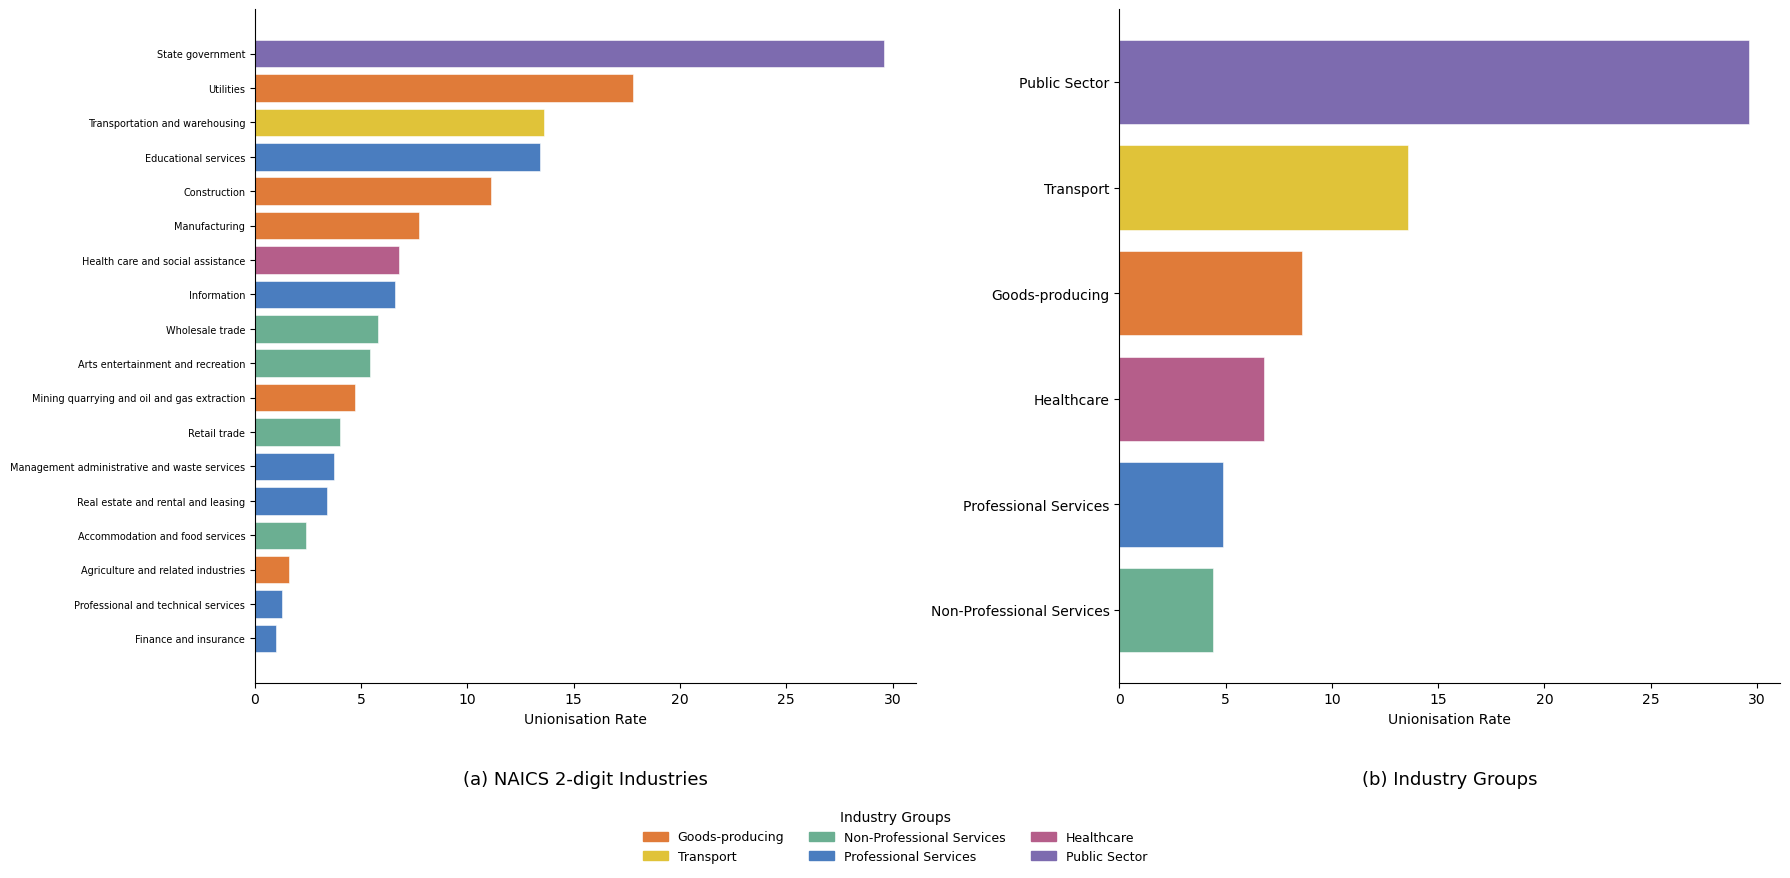

In [9]:
##########################################
###### Unionisation Rate by Industry #####
##########################################

# Packages
import pandas as pd

# Directory
directory = r'C:\Users\20234503\Dropbox\PhD Project\Research\Weather and Strikes\Project'

# =============================================================================
# (1) Unionisation Rate by Industry (Bureau of labour statistics)
# =============================================================================

unionisation_industry = pd.read_csv(
    directory + r"\Data\Raw\Union\union_membership_2025.csv",
)

# -----------------------------------------------------------------------------
# (2) Filtering to only sectors present in Labour Conflict Data
# -----------------------------------------------------------------------------
# Load the cleaned labour conflict event data
lconflict_event = pd.read_csv(directory + '\\Data\\lconflict_event.csv')
# Filter to Events Just in the United States (Contiguous US)
non_contiguous = ['Alaska', 'Hawaii', 'Puerto Rico', 'U.S. Virgin Islands', 'Guam', 'District of Columbia']
lconflict_event = lconflict_event[~lconflict_event['Location_State'].isin(non_contiguous)]
# Print the number of unique events and counties with events (In Summer)
lconflict_event['Start_date'] = pd.to_datetime(lconflict_event['Start_date'])
lconflict_event = lconflict_event[lconflict_event['Start_date'].dt.month.isin([6, 7, 8])]
#Filter to only sectors present in the labour conflict data
sectors_in_data = lconflict_event['NAICS_code_first'].unique()
unionisation_industry['in_data'] = unionisation_industry['NAICS_2digit'].isin(sectors_in_data).astype(int)

# -----------------------------------------------------------------------------
# (3) Agregate to Broad Sectors
# -----------------------------------------------------------------------------
# Map NAICS codes to broad sectors
naics_to_broad = {
    # Goods-producing
    '11': 'Goods-producing',
    '21': 'Goods-producing',
    '22': 'Goods-producing',
    '23': 'Goods-producing',
    '31': 'Goods-producing',
    '32': 'Goods-producing',
    '33': 'Goods-producing',
    # Professional Services
    '51': 'Professional Services',
    '52': 'Professional Services',
    '53': 'Professional Services',
    '54': 'Professional Services',
    '55': 'Professional Services',
    '61': 'Professional Services',
    # Non-Professional Services
    '42': 'Non-Professional Services',
    '44': 'Non-Professional Services',
    '45': 'Non-Professional Services',
    '56': 'Non-Professional Services',
    '71': 'Non-Professional Services',
    '72': 'Non-Professional Services',
    # Transport (separated due to high physical and weather exposure)
    '48': 'Transport',
    '49': 'Transport',
    # Healthcare
    '62': 'Healthcare',
    # Public Sector
    '92': 'Public Sector',
}

# Match on first 2 digits of NAICS code
unionisation_industry['Broad_Sector'] = (
    unionisation_industry['NAICS_2digit']
    .astype(str)
    .str[:2]
    .map(naics_to_broad)
)

# Average exposure index across all NAICS sectors within each broad sector
unionisation_industry_broad = (
    unionisation_industry
    .dropna(subset=['Broad_Sector'])
    .groupby('Broad_Sector', as_index=False)
    .agg(
        Avg_Members_of_unions_pct_2025 = ('Members_of_unions_pct_2025', 'mean')
    )
)

# =============================================================================
# (4) Visualisation — Composite Exposure Index Across Industries (Two Panels)
# =============================================================================

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Colour palette by industry group
industry_group_colours = {
    'Goods-producing'          : '#E07B39',
    'Transport'                : '#E0C339',
    'Non-Professional Services': '#6BAF92',
    'Professional Services'    : '#4A7DBF',
    'Healthcare'               : '#B55E8A',
    'Public Sector'            : '#7D6BAF',
}

# -----------------------------------------------------------------------------
# (6a) Prepare plot dataframes
# -----------------------------------------------------------------------------

# NAICS-level: drop missing, sort by exposure
unionisation_industry_plot = (
    unionisation_industry
    .dropna(subset=['Broad_Sector', 'Members_of_unions_pct_2025'])
    .sort_values('Members_of_unions_pct_2025', ascending=True)
)
unionisation_industry_plot['colour'] = unionisation_industry_plot['Broad_Sector'].map(industry_group_colours)

# Industry group-level: drop missing, sort by exposure
unionisation_industry_broad_plot = (
    unionisation_industry_broad
    .dropna(subset=['Broad_Sector', 'Avg_Members_of_unions_pct_2025'])
    .sort_values('Avg_Members_of_unions_pct_2025', ascending=True)
)
unionisation_industry_broad_plot['colour'] = unionisation_industry_broad_plot['Broad_Sector'].map(industry_group_colours)


# -----------------------------------------------------------------------------
# (6b) Plot
# -----------------------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# --- Panel (a): NAICS 2-digit Industries ---
axes[0].barh(
    unionisation_industry_plot['NAICS_sector'],
    unionisation_industry_plot['Members_of_unions_pct_2025'],
    color=unionisation_industry_plot['colour'],
    edgecolor='white',
    linewidth=0.4,
)
axes[0].set_xlabel('Unionisation Rate', fontsize=10)
axes[0].tick_params(axis='y', labelsize=7)
axes[0].spines[['top', 'right']].set_visible(False)
axes[0].set_title('')
axes[0].annotate('(a) NAICS 2-digit Industries', xy=(0.5, -0.15), xycoords='axes fraction',
                 ha='center', fontsize=13)

# --- Panel (b): Industry Groups ---
axes[1].barh(
    unionisation_industry_broad_plot['Broad_Sector'],
    unionisation_industry_broad_plot['Avg_Members_of_unions_pct_2025'],
    color=unionisation_industry_broad_plot['colour'],
    edgecolor='white',
    linewidth=0.4,
)
axes[1].set_xlabel('Unionisation Rate', fontsize=10)
axes[1].tick_params(axis='y', labelsize=10)
axes[1].spines[['top', 'right']].set_visible(False)
axes[1].set_title('')  # remove top title
axes[1].annotate('(b) Industry Groups', xy=(0.5, -0.15), xycoords='axes fraction',
                 ha='center', fontsize=13)

# Shared legend
legend_handles = [
    mpatches.Patch(color=col, label=group)
    for group, col in industry_group_colours.items()
]
fig.legend(
    handles=legend_handles,
    title='Industry Groups',
    loc='lower center',
    ncol=3,
    fontsize=9,
    title_fontsize=10,
    frameon=False,
    bbox_to_anchor=(0.5, -0.10),
)

plt.tight_layout()
plt.savefig(directory + r'\Results (Final)\unionisation_by_industry.png', dpi=300, bbox_inches='tight')
plt.show()

In [16]:
##############################################################################
###### Geographical Distribution of Labour Conflict Events (By Samples) ######
##############################################################################
# This script generates a map of the geographical distribution of labour conflict events.
# Panel (a) shows counties with at least one event over the study period (Full Sample) and 
# Panel (b) and (c) shows the distribution of events in the Preferred Model Sample and Robust Model Sample, respectively.

# Load necessary packages
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely import Point
from shapely.ops import unary_union

#Define the directory
directory = r'C:\Users\20234503\Dropbox\PhD Project\Research\Weather and Strikes\Project'

# Load the dataset
# (1) U.S. County Map
US_county_shp = gpd.read_file(directory+'\\Data\\Raw\\US Counties\\US_County_SHP\\c_05mr24.shp')
US_county_shp = gpd.GeoDataFrame(US_county_shp, geometry='geometry', crs="EPSG:4326")

US_county_shp = US_county_shp.to_crs("EPSG:5070")

# Define geographic bounding boxes for different regions (EPSG:5070) #Use GIS to identify the correct bounding boxes!
contiguous_bounds = [-2453691.2025, 171085.9341, 2365756.5659, 3381509.2103]

# Separate the regions based on bounding boxes
contiguous = US_county_shp.cx[contiguous_bounds[0]:contiguous_bounds[2],contiguous_bounds[1]:contiguous_bounds[3]]

# (2) County-Day Dataset
lconflict_weather_county_day = pd.read_csv(directory + '\\Data\\Weather_Labour_Unrest_Event.csv')

# Prepare the county-level data for mapping
lconflict_weather_county_day['date'] = pd.to_datetime(lconflict_weather_county_day['date'])
lconflict_weather_county_day = lconflict_weather_county_day[lconflict_weather_county_day['date'].dt.month.isin([6, 7, 8])]

# Load Samples Indicators Exported from Models (Used for Creating Panels (b) and (c)))
sample_indicators = pd.read_csv(directory + '\\Data\\model_samples.csv')
lconflict_weather_county_day = lconflict_weather_county_day.merge(
    sample_indicators,
    on='event_id',
    how='left'
)

fips_conflict = (
    lconflict_weather_county_day
    .groupby('FIPS')
    .agg(
        in_sample_m1=('in_sample_m1', 'max'),
        in_sample_m2=('in_sample_m2', 'max'),
    )
    .reset_index()
)
fips_conflict['any_labour_conflict'] = 1

contiguous['FIPS'] = contiguous['FIPS'].astype('int64')
contiguous_county_events = contiguous.merge(fips_conflict, on='FIPS', how='left')
contiguous_county_events['any_labour_conflict'] = contiguous_county_events['any_labour_conflict'].fillna(0).astype(int)
contiguous_county_events['in_sample_m1'] = contiguous_county_events['in_sample_m1'].fillna(0).astype(int)
contiguous_county_events['in_sample_m2'] = contiguous_county_events['in_sample_m2'].fillna(0).astype(int)

c:\Users\20234503\AppData\Local\anaconda3\envs\Labour_Unrest_Weather_Env\Lib\site-packages\geopandas\geodataframe.py:1819: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)
